# آماده‌سازی داده

In [1]:
!pip install hazm

  Preparing metadata (setup.py) ... done
... [2 dependency check lines compacted] ...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 2.3 MB/s eta 0:00:00
... [4 dependency check lines compacted] ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 892.6/892.6 kB 16.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 94.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 93.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.6/38.6 MB 48.1 MB/s eta 0:00:00:00:0100:01
  Created wheel for flashtext: filename=flashtext-2.7-py2.py3-none-any.whl size=9300 sha256=94095f84b32c005832d5b87b78cb8e4111ddb4b6db5954bf12d71d3e507e2b17
  Stored in directory: /root/.cache/pip/wheels/49/20/47/f03dfa8a7239c54cbc44ff7389eefbf888d2c1873edaaec888
Successfully built flashtext
  Attempting uninstall: numpy
    Found existing installation: num

In [2]:
!pip install arabic_reshaper python-bidi

In [3]:
import os
import pandas as pd
from PIL import Image
import numpy as np
from hazm import Normalizer
import string
from tqdm import tqdm

CSV_PATH='/kaggle/input/coco-captions/dataset/data.csv'
IMAGE_BASE_DIR='/kaggle/input/coco-captions/dataset/images/'
PROCESSED_IMAGE_DIR='/kaggle/working/processed_images/'
IMAGE_COLUMN='image'
CAPTION_COLUMN='text'

tqdm.pandas()

if not os.path.exists(PROCESSED_IMAGE_DIR):
    os.makedirs(PROCESSED_IMAGE_DIR)

text_normalizer=Normalizer()

def process_and_save_image(filename,size=(224,224)):
    if pd.isna(filename):
        return None
    try:
        source_path=os.path.join(IMAGE_BASE_DIR,filename)
        
        npy_filename=os.path.splitext(filename)[0]+'.npy'
        output_path=os.path.join(PROCESSED_IMAGE_DIR,npy_filename)
        
        img=Image.open(source_path).convert('RGB')
        resized_img=img.resize(size)
        img_array=np.array(resized_img)
        normalized_img_array=img_array/255.0
        
        np.save(output_path,normalized_img_array.astype(np.float32))
        
        return output_path
    except Exception as e:
        return None

print(f"Reading CSV from: {CSV_PATH}")
df_full=pd.read_csv(CSV_PATH)
df_intermediate=df_full.head(20000).copy()
del df_full
print(f"Processing the first {len(df_intermediate)} rows.")

print("Normalizing Persian text and removing punctuation...")
persian_punctuation='،؛؟«»'
all_punctuation=string.punctuation+persian_punctuation
translation_table=str.maketrans('','',all_punctuation)
df_intermediate['normalized_caption']=df_intermediate[CAPTION_COLUMN].apply(
    lambda text:text_normalizer.normalize(str(text)).translate(translation_table)
)

print("Validating image paths...")
def check_path(filename):
    return os.path.exists(os.path.join(IMAGE_BASE_DIR,filename))

df_intermediate=df_intermediate[df_intermediate[IMAGE_COLUMN].apply(check_path)].copy()
print(f"Found {len(df_intermediate)} valid images to process.")

print("Processing images and saving to disk...")
df_intermediate['processed_image_path']=df_intermediate[IMAGE_COLUMN].progress_apply(process_and_save_image)

df_intermediate.dropna(subset=['processed_image_path'],inplace=True)

df_captions=df_intermediate[[IMAGE_COLUMN,'normalized_caption','processed_image_path']].reset_index(drop=True)
del df_intermediate

print("\nPreprocessing complete.")
print("\n`df_captions` (DataFrame with image names, captions, and paths):")
print(df_captions.head())
print(f"\nShape of df_captions: {df_captions.shape}")

Reading CSV from: /kaggle/input/coco-captions/dataset/data.csv
Processing the first 20000 rows.
Normalizing Persian text and removing punctuation...
Validating image paths...
Found 20000 valid images to process.
Processing images and saving to disk...


100%|██████████| 20000/20000 [03:07<00:00, 106.74it/s]


Preprocessing complete.

`df_captions` (DataFrame with image names, captions, and paths):
           image                                 normalized_caption  \
0  img_00000.jpg  شخصی که با سگی راه می‌رود می‌ایستد تا به میز ک...
1  img_00001.jpg                زنی با دو سگ در حال بازی فریزبی است
2  img_00002.jpg                       سگی با چیزی در دهانش روی تخت
3  img_00003.jpg  یک موس کامپیوتر سیاه روی میزی کنار چند دی وی د...
4  img_00004.jpg       یک بشقاب لوبیا تخم‌مرغ و نان تست روی میز است

                             processed_image_path
0  /kaggle/working/processed_images/img_00000.npy
1  /kaggle/working/processed_images/img_00001.npy
2  /kaggle/working/processed_images/img_00002.npy
3  /kaggle/working/processed_images/img_00003.npy
4  /kaggle/working/processed_images/img_00004.npy

Shape of df_captions: (20000, 3)


In [4]:
from collections import Counter
from hazm import word_tokenize

class Vocabulary:
    def __init__(self,freq_threshold):
        self.itos={0:"<pad>",1:"<sos>",2:"<eos>",3:"<unk>"}
        self.stoi={"<pad>":0,"<sos>":1,"<eos>":2,"<unk>":3}
        self.freq_threshold=freq_threshold

    def __len__(self):
        return len(self.itos)

    def build_vocabulary(self,sentence_list):
        frequencies=Counter()
        idx=4
        for sentence in sentence_list:
            for word in word_tokenize(sentence):
                frequencies[word]+=1
        for word,count in frequencies.items():
            if count>=self.freq_threshold:
                self.stoi[word]=idx
                self.itos[idx]=word
                idx+=1

    def numericalize(self,text):
        tokenized_text=word_tokenize(text)
        return [self.stoi.get(token,self.stoi["<unk>"]) for token in tokenized_text]


print("Building vocabulary...")
vocab=Vocabulary(freq_threshold=3)
vocab.build_vocabulary(df_captions['normalized_caption'].tolist())
print(f"Vocabulary built. Total unique tokens: {len(vocab)}")


print("Numericalizing captions...")
def numericalize_and_add_tokens(text,vocab):
    numericalized=vocab.numericalize(text)
    return [vocab.stoi["<sos>"]]+numericalized+[vocab.stoi["<eos>"]]

df_captions['numerical_caption']=df_captions['normalized_caption'].apply(
    lambda text:numericalize_and_add_tokens(text,vocab)
)


print("\n`vocab` (Vocabulary object):")
print(f"Vocabulary size: {len(vocab)}")
print("Example word-to-index mapping:",list(vocab.stoi.items())[:10])

print("\n`df_captions` (DataFrame is now updated with numerical captions):")
print(df_captions.head())

Building vocabulary...
Vocabulary built. Total unique tokens: 3192
Numericalizing captions...

`vocab` (Vocabulary object):
Vocabulary size: 3192
Example word-to-index mapping: [('<pad>', 0), ('<sos>', 1), ('<eos>', 2), ('<unk>', 3), ('شخصی', 4), ('که', 5), ('با', 6), ('سگی', 7), ('راه', 8), ('می\u200cرود', 9)]

`df_captions` (DataFrame is now updated with numerical captions):
           image                                 normalized_caption  \
0  img_00000.jpg  شخصی که با سگی راه می‌رود می‌ایستد تا به میز ک...
1  img_00001.jpg                زنی با دو سگ در حال بازی فریزبی است
2  img_00002.jpg                       سگی با چیزی در دهانش روی تخت
3  img_00003.jpg  یک موس کامپیوتر سیاه روی میزی کنار چند دی وی د...
4  img_00004.jpg       یک بشقاب لوبیا تخم‌مرغ و نان تست روی میز است

                             processed_image_path  \
0  /kaggle/working/processed_images/img_00000.npy
1  /kaggle/working/processed_images/img_00001.npy
2  /kaggle/working/processed_images/img_00002.npy
3  /k

In [5]:
import torch
from torch.utils.data import Dataset,DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split
import os
import numpy as np
import pandas as pd

train_df,temp_df=train_test_split(
    df_captions,
    test_size=0.2,
    random_state=42
)
val_df,test_df=train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42
)

class FlickrDataset(Dataset):
    def __init__(self,captions_df):
        self.df=captions_df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        img_path=self.df.at[idx,'processed_image_path']
        
        image=np.load(img_path)
        
        image_tensor=torch.tensor(image,dtype=torch.float32).permute(2,0,1)
        
        caption=torch.tensor(self.df.at[idx,'numerical_caption'],dtype=torch.long)
        caption_len=torch.tensor(len(caption),dtype=torch.long)
        
        return image_tensor,caption,caption_len
        
class PadCollate:
    def __init__(self,pad_idx):
        self.pad_idx=pad_idx

    def __call__(self,batch):
        images=[item[0] for item in batch]
        images=torch.stack(images,dim=0)
        captions=[item[1] for item in batch]
        captions_padded=pad_sequence(captions,batch_first=True,padding_value=self.pad_idx)
        caption_lens=[item[2] for item in batch]
        caption_lens=torch.stack(caption_lens,dim=0)
        return images,captions_padded,caption_lens

BATCH_SIZE=32
PAD_IDX=vocab.stoi["<pad>"]

train_dataset=FlickrDataset(train_df)
val_dataset=FlickrDataset(val_df)
test_dataset=FlickrDataset(test_df)

train_loader=DataLoader(dataset=train_dataset,batch_size=BATCH_SIZE,shuffle=True,collate_fn=PadCollate(pad_idx=PAD_IDX),num_workers=os.cpu_count(),pin_memory=True)
val_loader=DataLoader(dataset=val_dataset,batch_size=BATCH_SIZE,shuffle=False,collate_fn=PadCollate(pad_idx=PAD_IDX),num_workers=os.cpu_count(),pin_memory=True)
test_loader=DataLoader(dataset=test_dataset,batch_size=BATCH_SIZE,shuffle=False,collate_fn=PadCollate(pad_idx=PAD_IDX),num_workers=os.cpu_count(),pin_memory=True)

criterion=torch.nn.CrossEntropyLoss(ignore_index=PAD_IDX)
print("---DataLoaders are Ready---")
print(f"Train dataset size: {len(train_dataset)}")
print(f"Num workers for parallel loading: {os.cpu_count()}")

---DataLoaders are Ready---
Train dataset size: 16000
Num workers for parallel loading: 4


Displaying random samples...


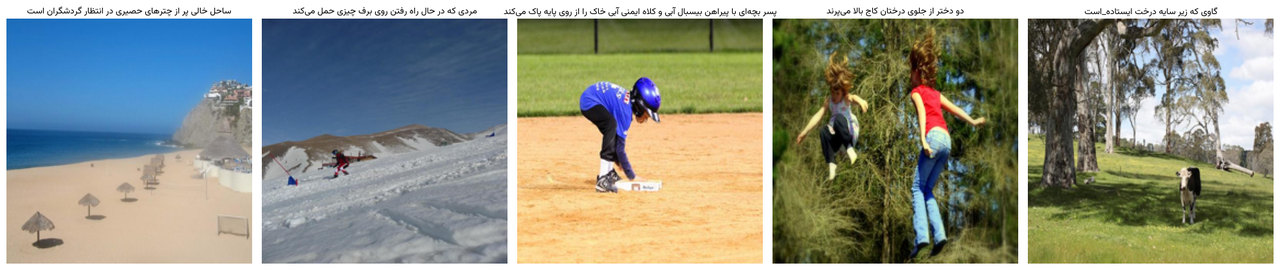

Generating histogram of caption lengths...


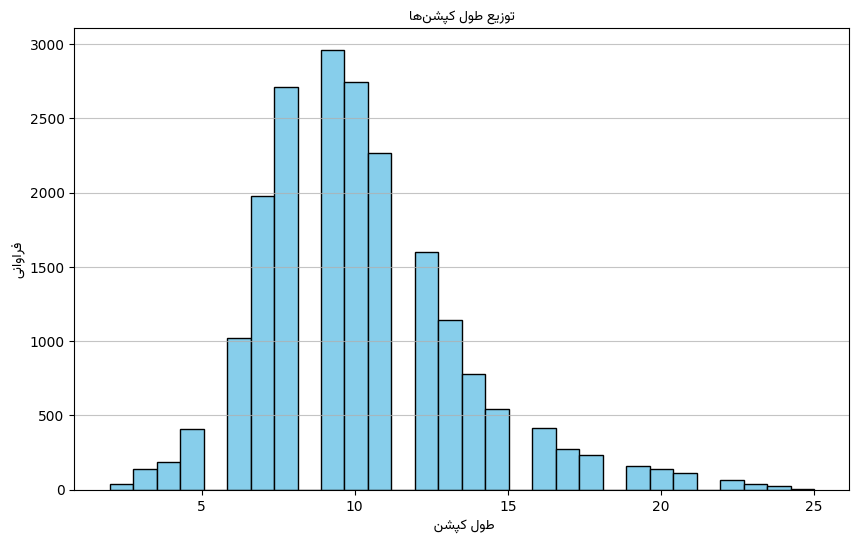

Finding the 10 most repeated words...


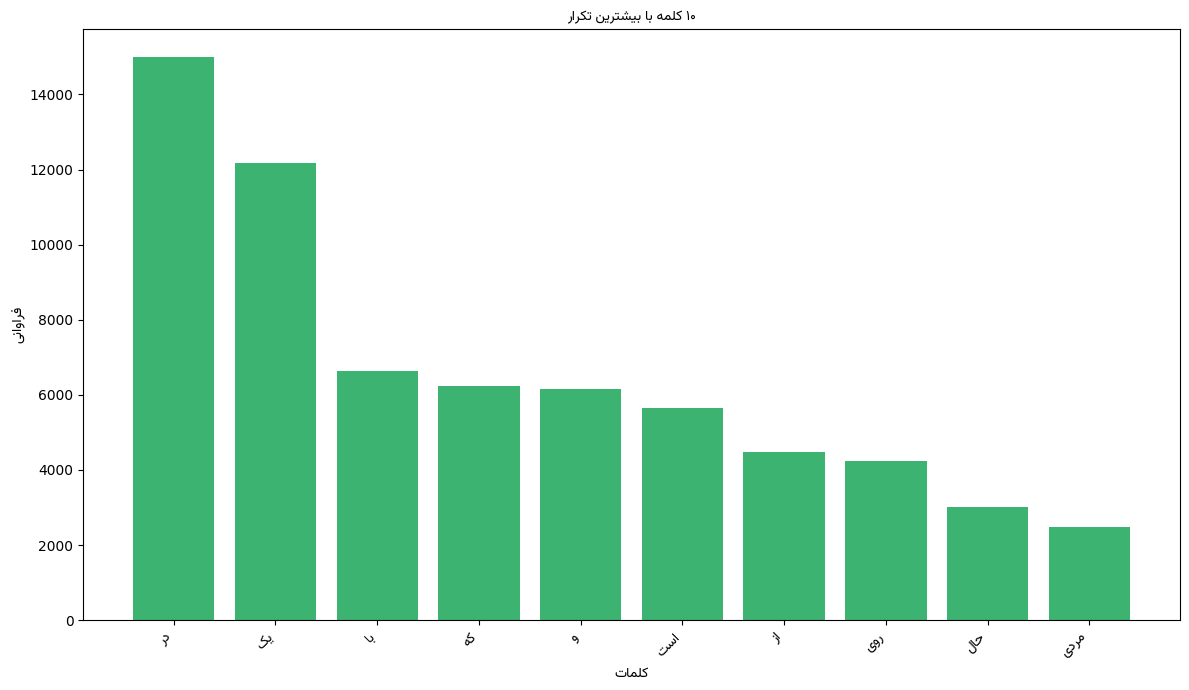

Total number of unique words in the vocabulary: 3192


In [20]:
import matplotlib.pyplot as plt
import random
from collections import Counter
import pandas as pd
import arabic_reshaper
from bidi.algorithm import get_display
from matplotlib.font_manager import FontProperties

persian_font_path='/kaggle/input/vazirmatn/Vazirmatn-VariableFont_wght.ttf'
persian_font=FontProperties(fname=persian_font_path)

def display_samples(dataset,num_samples=5):
    fig,axes=plt.subplots(1,num_samples,figsize=(20,5))
    for i in range(num_samples):
        idx=random.randint(0,len(dataset)-1)
        image,caption_indices,_=dataset[idx]
        caption_words=[vocab.itos[idx.item()] for idx in caption_indices]
        clean_caption=' '.join(word for word in caption_words if word not in ["<sos>","<eos>","<pad>"])
        
        reshaped_text=arabic_reshaper.reshape(clean_caption)
        bidi_text=get_display(reshaped_text)
        
        ax=axes[i]
        image_for_plot=image.permute(1,2,0)
        ax.imshow(image_for_plot)
        ax.set_title(bidi_text,fontproperties=persian_font,wrap=True,fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.savefig("sample_images_with_captions_correct.png")
    plt.show()

print("Displaying random samples...")
display_samples(train_dataset,num_samples=5)


print("\nGenerating histogram of caption lengths...")
caption_lengths=df_captions['numerical_caption'].apply(lambda x:len(x)-2)
plt.figure(figsize=(10,6))
plt.hist(caption_lengths,bins=30,color='skyblue',edgecolor='black')


title_text="توزیع طول کپشن‌ها" 
plt.title(get_display(arabic_reshaper.reshape(title_text)),fontproperties=persian_font)
plt.xlabel(get_display(arabic_reshaper.reshape("طول کپشن ")),fontproperties=persian_font)
plt.ylabel(get_display(arabic_reshaper.reshape("فراوانی")),fontproperties=persian_font)

plt.grid(axis='y',alpha=0.75)
plt.savefig("caption_length_histogram_correct.png")
plt.show()


print("\nFinding the 10 most repeated words...")
all_words=[]
for caption in df_captions['normalized_caption']:
    all_words.extend(caption.split())
word_counts=Counter(all_words)
most_common_words=word_counts.most_common(10)
top_words_df=pd.DataFrame(most_common_words,columns=['Word','Count'])

reshaped_labels=[get_display(arabic_reshaper.reshape(label)) for label in top_words_df['Word']]

plt.figure(figsize=(12,7))
plt.bar(top_words_df['Word'],top_words_df['Count'],color='mediumseagreen')

plt.title(get_display(arabic_reshaper.reshape("۱۰ کلمه با بیشترین تکرار")),fontproperties=persian_font)
plt.xlabel(get_display(arabic_reshaper.reshape("کلمات")),fontproperties=persian_font)
plt.ylabel(get_display(arabic_reshaper.reshape("فراوانی")),fontproperties=persian_font)
plt.xticks(ticks=top_words_df['Word'],labels=reshaped_labels,rotation=45,ha='right',fontproperties=persian_font)

plt.tight_layout()
plt.savefig("most_common_words_correct.png")
plt.show()


# --- 6. Number of Unique Words ---
print(f"\nTotal number of unique words in the vocabulary: {len(vocab)}")

# RNN+CNN

In [52]:
import torch
import torch.nn as nn
import torchvision.models as models

class Encoder(nn.Module):

    def __init__(self,train_cnn=False):
        super(Encoder,self).__init__()
        efficientnet=models.efficientnet_b7(weights=models.EfficientNet_B7_Weights.DEFAULT)
        
        self.features=efficientnet.features
        self.avgpool=efficientnet.avgpool
        
        if not train_cnn:
            for param in self.features.parameters():
                param.requires_grad=False

    def forward(self,images):
        features=self.features(images) 
        
        batch_size,channels,height,width=features.size()
        features=features.view(batch_size,channels,-1)
        features=features.permute(0,2,1)
        return features

class Attention(nn.Module):

    def __init__(self,encoder_dim,decoder_dim,attention_dim):
        super(Attention,self).__init__()
        self.encoder_att=nn.Linear(encoder_dim,attention_dim)
        self.decoder_att=nn.Linear(decoder_dim,attention_dim)
        self.full_att=nn.Linear(attention_dim,1)
        self.relu=nn.ReLU()
        self.softmax=nn.Softmax(dim=1)

    def forward(self,encoder_out,decoder_hidden):
        att1=self.encoder_att(encoder_out)
        att2=self.decoder_att(decoder_hidden)
        
        combined_att=self.relu(att1+att2.unsqueeze(1))
        
        att_scores=self.full_att(combined_att).squeeze(2)
        
        alpha=self.softmax(att_scores)
        
        context_vector=(encoder_out*alpha.unsqueeze(2)).sum(dim=1)
        
        return context_vector,alpha

class Decoder(nn.Module):

    def __init__(self,embed_dim,decoder_dim,vocab_size,encoder_dim=2560,dropout=0.5):
        super(Decoder,self).__init__()
        self.encoder_dim=encoder_dim
        self.attention=Attention(encoder_dim,decoder_dim,decoder_dim)
        
        self.embedding=nn.Embedding(vocab_size,embed_dim)
        
        self.dropout=nn.Dropout(p=dropout)
        
        self.decode_step=nn.LSTMCell(embed_dim+encoder_dim,decoder_dim,bias=True)
        

        self.init_h=nn.Linear(encoder_dim,decoder_dim)
        self.init_c=nn.Linear(encoder_dim,decoder_dim)
        
        self.fc=nn.Linear(decoder_dim,vocab_size)
        
    def init_hidden_state(self,encoder_out):
        mean_encoder_out=encoder_out.mean(dim=1)
        h=self.init_h(mean_encoder_out)
        c=self.init_c(mean_encoder_out)
        return h,c

    def forward(self,encoder_out,encoded_captions,caption_lengths):
        batch_size=encoder_out.size(0)
        vocab_size=self.fc.out_features
        
        embeddings=self.embedding(encoded_captions)
        
        h,c=self.init_hidden_state(encoder_out)
        
        decode_lengths=[l-1 for l in caption_lengths]
        
        predictions=torch.zeros(batch_size,max(decode_lengths),vocab_size).to(encoder_out.device)
        
        for t in range(max(decode_lengths)):
            batch_size_t=sum([l>t for l in decode_lengths])
            
            context_vector,_=self.attention(encoder_out[:batch_size_t],h[:batch_size_t])
            
            lstm_input=torch.cat((embeddings[:batch_size_t,t,:],context_vector),dim=1)
            
            h,c=self.decode_step(lstm_input,(h[:batch_size_t],c[:batch_size_t]))
            
            preds=self.fc(self.dropout(h))
            predictions[:batch_size_t,t,:]=preds
            
        return predictions

class ImageCaptioningModel(nn.Module):
    def __init__(self,embed_dim,decoder_dim,vocab_size,encoder_dim=2560,dropout=0.5):
        super(ImageCaptioningModel,self).__init__()
        self.encoder=Encoder()
        self.decoder=Decoder(embed_dim,decoder_dim,vocab_size,encoder_dim,dropout)
        
    def forward(self,images,captions,caption_lengths):
        encoder_out=self.encoder(images)
        outputs=self.decoder(encoder_out,captions,caption_lengths)
        return outputs

embed_dim=512
decoder_dim=512
vocab_size=3192 
dropout=0.5

model=ImageCaptioningModel(embed_dim=embed_dim,decoder_dim=decoder_dim,vocab_size=vocab_size,dropout=dropout)

total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 78,599,753
Trainable parameters: 14,812,793


# آموزش و ارزیابی

In [53]:
import torch
import gc
gc.collect()

torch.cuda.empty_cache()

print("GPU memory cache cleared.")

GPU memory cache cleared.


Using device: cuda
--- Using 2 GPUs! ---
Model, Loss, Optimizer, and LR Scheduler are ready.

--- Starting Training with Effective Batch Size: 32 ---


Epoch 1/20 -> Train Loss: 2.5845, Val Loss: 4.4479


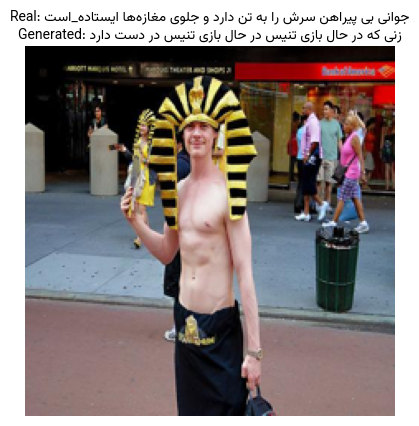

Epoch 2/20 -> Train Loss: 2.1287, Val Loss: 4.0481


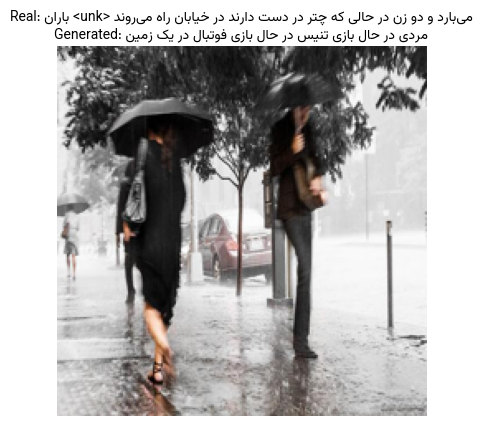

Epoch 3/20 -> Train Loss: 1.9603, Val Loss: 3.8578


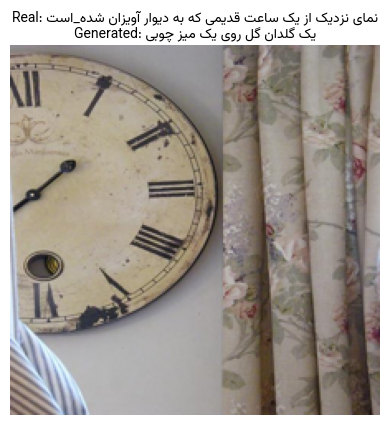

Epoch 4/20 -> Train Loss: 1.8487, Val Loss: 3.7451


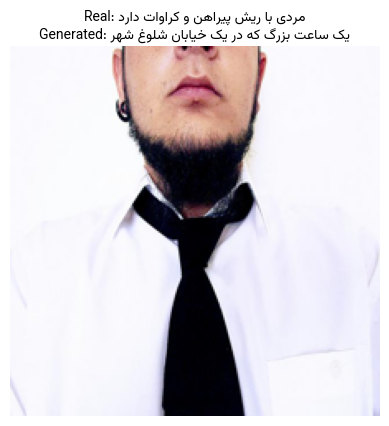

Epoch 5/20 -> Train Loss: 1.7678, Val Loss: 3.6708


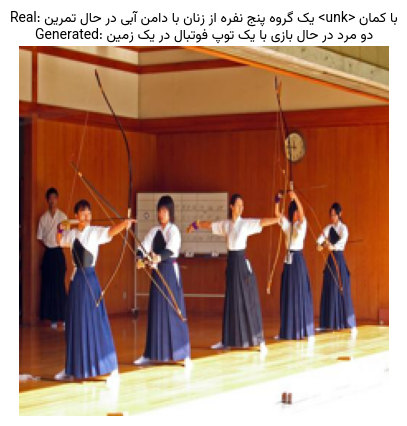

Epoch 6/20 -> Train Loss: 1.6954, Val Loss: 3.6201


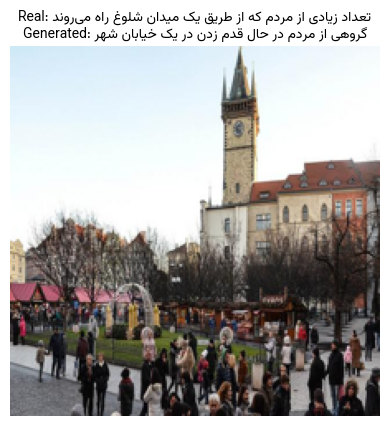

Epoch 7/20 -> Train Loss: 1.6377, Val Loss: 3.5845


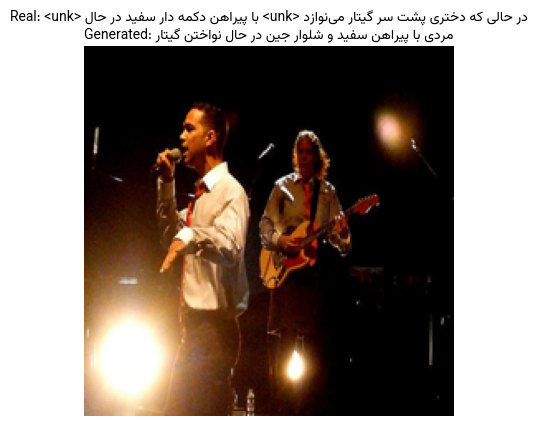

Epoch 8/20 -> Train Loss: 1.5790, Val Loss: 3.5618


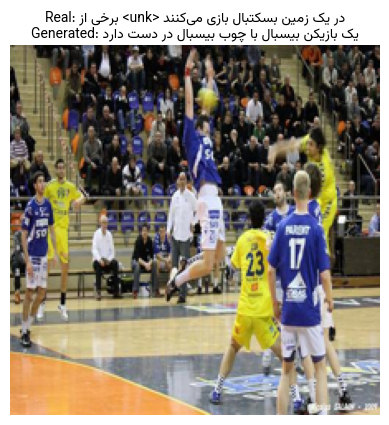

Epoch 9/20 -> Train Loss: 1.5295, Val Loss: 3.5560


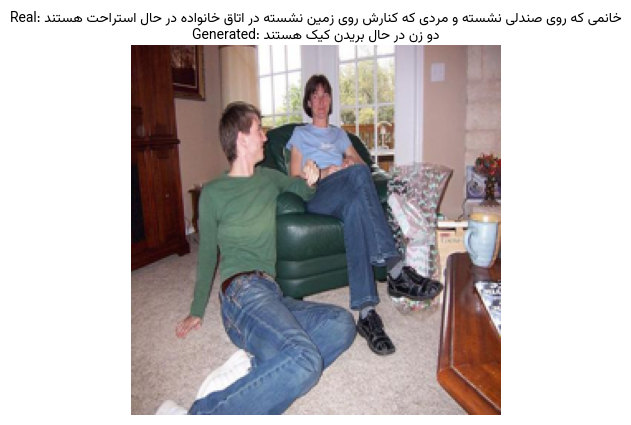

Epoch 10/20 -> Train Loss: 1.4862, Val Loss: 3.5461


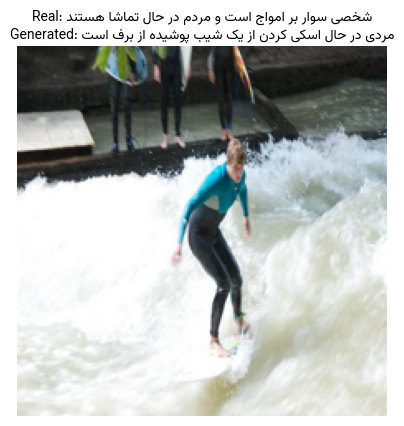

Epoch 11/20 -> Train Loss: 1.4412, Val Loss: 3.5341


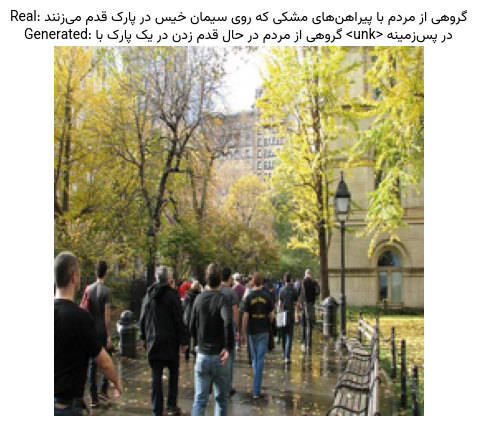

Epoch 12/20 -> Train Loss: 1.3949, Val Loss: 3.5475


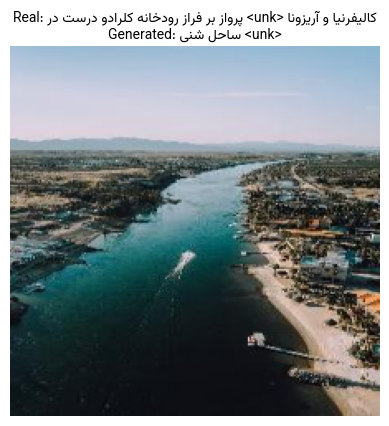

Epoch 13/20 -> Train Loss: 1.3585, Val Loss: 3.5504


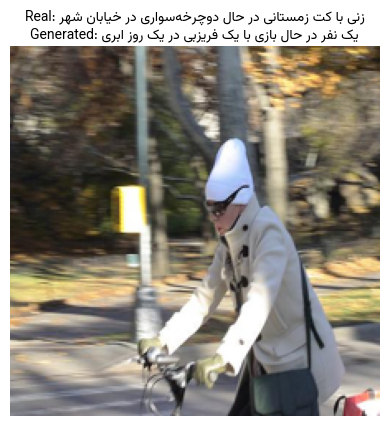

Epoch 14/20 -> Train Loss: 1.3225, Val Loss: 3.5549


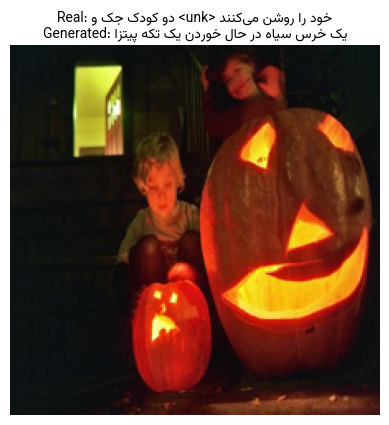

Epoch 16/20 -> Train Loss: 1.2427, Val Loss: 3.5302


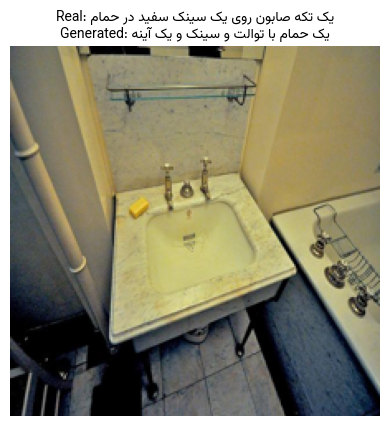

Epoch 17/20 -> Train Loss: 1.1943, Val Loss: 3.5402


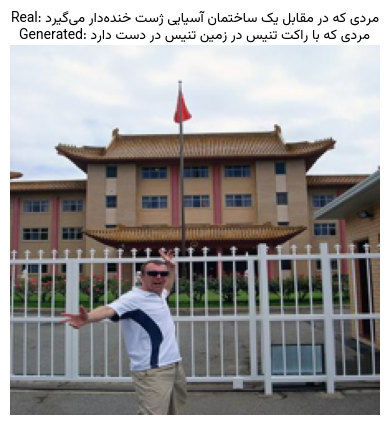

Epoch 18/20 -> Train Loss: 1.1518, Val Loss: 3.5485


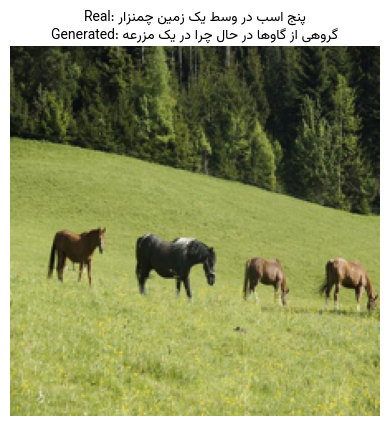

Epoch 19/20 -> Train Loss: 1.1153, Val Loss: 3.5709


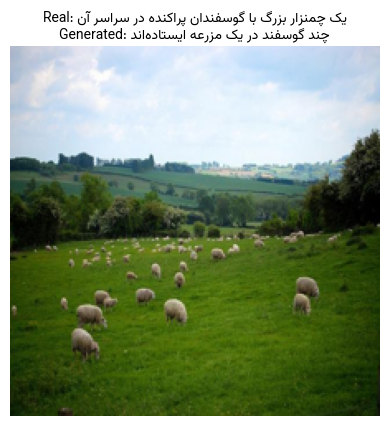

Epoch 20/20 -> Train Loss: 1.0596, Val Loss: 3.5698


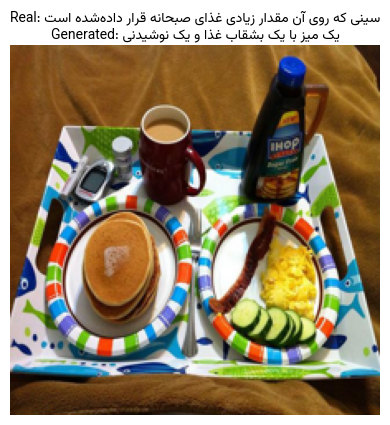

--- Training Complete: Plotting Loss Curves ---


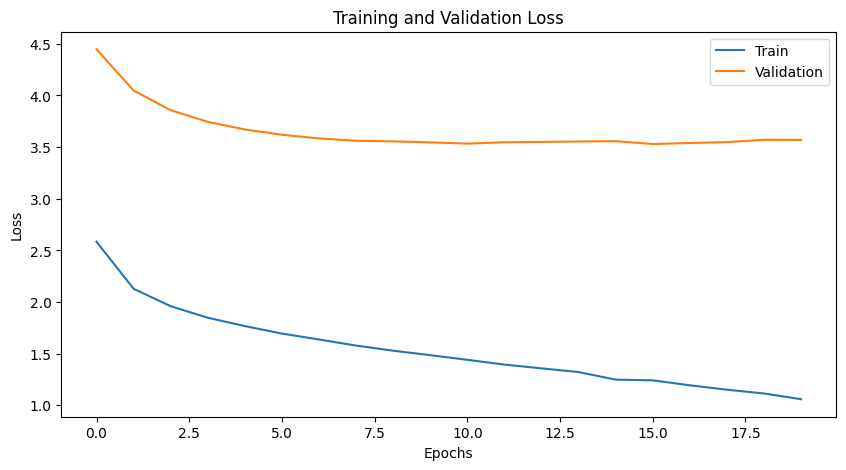

In [54]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display
import random
from matplotlib.font_manager import FontProperties

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

vocab_size=len(vocab)
embed_dim=512
decoder_dim=512
encoder_dim=2560
dropout=0.5

epochs=20
BATCH_SIZE=16 
ACCUMULATION_STEPS=2
fine_tune_epoch=15
learning_rate=5e-4
fine_tune_lr=1e-4
weight_decay=1e-4
grad_clip=5.0


model=ImageCaptioningModel(
    embed_dim=embed_dim,
    decoder_dim=decoder_dim,
    vocab_size=vocab_size,
    encoder_dim=encoder_dim,
    dropout=dropout
)

if torch.cuda.device_count()>1:
    print(f"--- Using {torch.cuda.device_count()} GPUs! ---")
    model=nn.DataParallel(model)

model.to(device)

criterion=nn.CrossEntropyLoss(ignore_index=vocab.stoi["<pad>"])
optimizer=torch.optim.AdamW(filter(lambda p:p.requires_grad,model.parameters()),lr=learning_rate,weight_decay=weight_decay)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.1,patience=2,verbose=True)
print("Model, Loss, Optimizer, and LR Scheduler are ready.")

def generate_example_caption(model,dataset,vocab):
    model.eval()
    with torch.no_grad():
        idx=random.randint(0,len(dataset)-1)
        image,caption_true, _ =dataset[idx]
        image_for_model=image.unsqueeze(0).to(device)
        real_caption=' '.join([vocab.itos[idx.item()] for idx in caption_true if idx.item() not in [0,1,2]])
        
        features=model.module.encoder(image_for_model)
        h,c=model.module.decoder.init_hidden_state(features)
        
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        for _ in range(30):
            embeddings=model.module.decoder.embedding(input_word)
            context_vector,_=model.module.decoder.attention(features,h)
            lstm_input=torch.cat((embeddings,context_vector),dim=1)
            h,c=model.module.decoder.decode_step(lstm_input,(h,c))
            output=model.module.decoder.fc(h)
            predicted_word_idx=output.argmax(1)
            result_caption.append(predicted_word_idx.item())
            if predicted_word_idx.item()==vocab.stoi['<eos>']: break
            input_word=predicted_word_idx
        generated_caption=' '.join([vocab.itos[idx] for idx in result_caption if idx not in [0,1,2]])
        image_for_plot=image.permute(1,2,0).cpu().numpy()
        plt.imshow(image_for_plot)
        real_caption_display=get_display(arabic_reshaper.reshape(f"Real: {real_caption}"))
        gen_caption_display=get_display(arabic_reshaper.reshape(f"Generated: {generated_caption}"))
        plt.title(f"{real_caption_display}\n{gen_caption_display}",fontproperties=persian_font)
        plt.axis('off')
        plt.show()
    model.train()

train_losses=[]
val_losses=[]
print(f"\n--- Starting Training with Effective Batch Size: {BATCH_SIZE*ACCUMULATION_STEPS} ---")

for epoch in range(epochs):
    if epoch==fine_tune_epoch:
        print("\n--- Unfreezing Encoder and starting Fine-Tuning ---")
        for param in model.module.encoder.parameters():
            param.requires_grad=True
        optimizer=torch.optim.AdamW(model.parameters(),lr=fine_tune_lr,weight_decay=weight_decay)
        scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.1,patience=2,verbose=True)

    model.train()
    loop=tqdm(train_loader,total=len(train_loader),leave=False)
    loop.set_description(f"Epoch [{epoch+1}/{epochs}] Training")
    total_loss_train=0
    optimizer.zero_grad()
    
    for i,(images,captions,caption_lengths) in enumerate(loop):
        images,captions=images.to(device),captions.to(device)
        
        outputs=model(images,captions,caption_lengths.cpu().tolist())
        
        targets=captions[:,1:]
        loss=criterion(outputs.reshape(-1,vocab_size),targets.reshape(-1))
        loss=loss/ACCUMULATION_STEPS
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),grad_clip)
        
        if (i+1)%ACCUMULATION_STEPS==0 or (i+1)==len(train_loader):
            optimizer.step()
            optimizer.zero_grad()
            
        total_loss_train+=loss.item()
        loop.set_postfix(loss=loss.item()*ACCUMULATION_STEPS)
        
    train_losses.append(total_loss_train/len(train_loader))
    model.eval()
    total_loss_val=0
    with torch.no_grad():
        for images,captions,caption_lengths in val_loader:
            images,captions=images.to(device),captions.to(device)
            outputs=model(images,captions,caption_lengths.cpu().tolist())
            targets=captions[:,1:]
            loss_val=criterion(outputs.reshape(-1,vocab_size),targets.reshape(-1))
            total_loss_val+=loss_val.item()
    val_losses.append(total_loss_val/len(val_loader))
    
    scheduler.step(val_losses[-1])
    
    print(f"\nEpoch {epoch+1}/{epochs} -> Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")
    generate_example_caption(model,val_dataset,vocab)


print("\n--- Training Complete: Plotting Loss Curves ---")
plt.figure(figsize=(10,5))
plt.title("Training and Validation Loss")
plt.plot(train_losses,label="Train")
plt.plot(val_losses,label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

--- Evaluating Model on the Entire Test Set ---


100%|██████████| 63/63 [03:15<00:00,  3.10s/it]


--- Overall Test Set BLEU Scores ---
Greedy Search -> BLEU-1: 0.2445 | BLEU-4: 0.0438
Beam Search (k=3) -> BLEU-1: 0.2349 | BLEU-4: 0.0461

--- Generating and Evaluating 5 Random Test Images ---


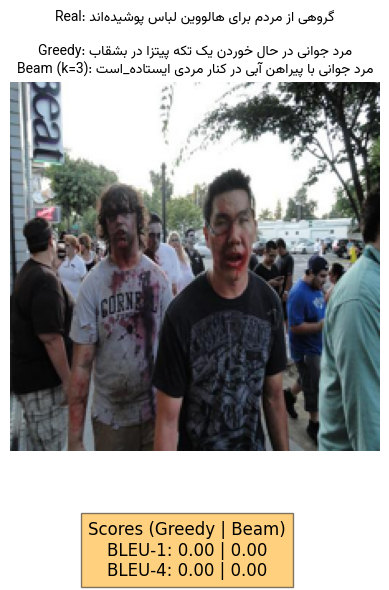

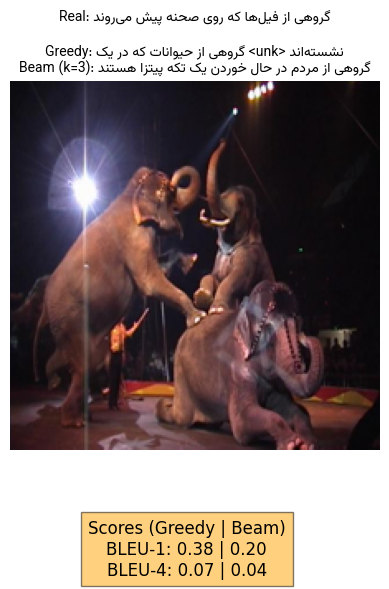

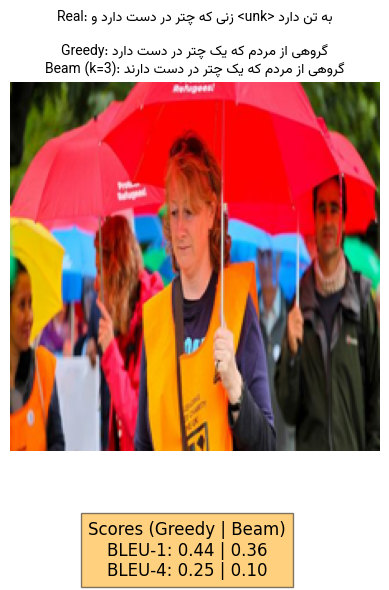

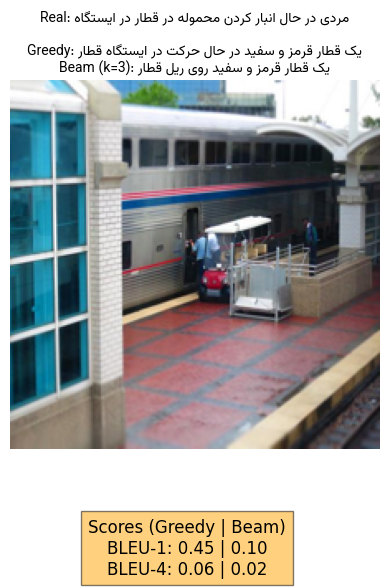

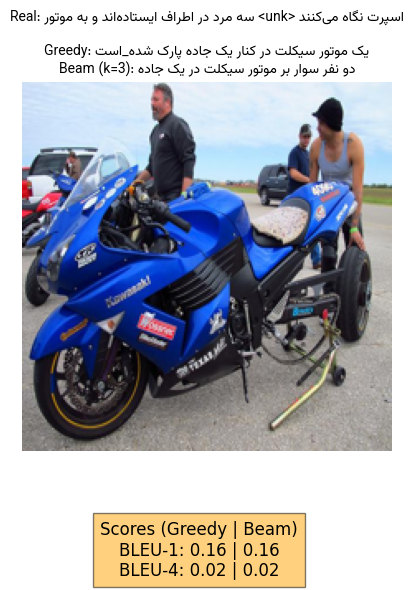

In [55]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
from nltk.translate.bleu_score import sentence_bleu,corpus_bleu,SmoothingFunction
from tqdm import tqdm
import torch.nn as nn 


DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")

import arabic_reshaper
from bidi.algorithm import get_display


def greedy_search_caption(model,image_tensor,vocab,device):
    is_parallel=(isinstance(model,nn.DataParallel))
    
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if is_parallel else model
        
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        for _ in range(30):
            embeds=model_to_use.decoder.embedding(input_word)
            context,_=model_to_use.decoder.attention(features,h)
            lstm_in=torch.cat((embeds,context),dim=1)
            h,c=model_to_use.decoder.decode_step(lstm_in,(h,c))
            output=model_to_use.decoder.fc(h)
            pred_idx=output.argmax(1)
            result_caption.append(pred_idx.item())
            if pred_idx.item()==vocab.stoi['<eos>']: break
            input_word=pred_idx
        return [vocab.itos[idx] for idx in result_caption if idx not in [0,1,2]]

def beam_search_caption(model,image_tensor,vocab,device,beam_width=3):
    is_parallel=(isinstance(model,nn.DataParallel))
    
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if is_parallel else model
        
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        k_sequences=[([vocab.stoi['<sos>']],0.0,h,c)]
        for _ in range(30):
            all_candidates=[]
            for seq,score,h_prev,c_prev in k_sequences:
                if seq[-1]==vocab.stoi['<eos>']:
                    all_candidates.append((seq,score,h_prev,c_prev))
                    continue
                input_word=torch.tensor([seq[-1]]).to(device)
                embeds=model_to_use.decoder.embedding(input_word)
                context,_=model_to_use.decoder.attention(features,h_prev)
                lstm_in=torch.cat((embeds,context),dim=1)
                h_next,c_next=model_to_use.decoder.decode_step(lstm_in,(h_prev,c_prev))
                output=model_to_use.decoder.fc(h_next)
                log_probs=torch.nn.functional.log_softmax(output,dim=1)
                top_log_probs,top_indices=log_probs.topk(beam_width,dim=1)
                for i in range(beam_width):
                    next_word_idx=top_indices[0][i].item()
                    new_score=score+top_log_probs[0][i].item()
                    new_seq=seq+[next_word_idx]
                    all_candidates.append((new_seq,new_score,h_next,c_next))
            ordered=sorted(all_candidates,key=lambda x:x[1],reverse=True)
            k_sequences=ordered[:beam_width]
            if all(s[0][-1]==vocab.stoi['<eos>'] for s in k_sequences): break
        best_seq_indices=k_sequences[0][0]
        return [vocab.itos[idx] for idx in best_seq_indices if idx not in [0,1,2]]

print("\n--- Evaluating Model on the Entire Test Set ---")
model.eval()
greedy_hypotheses=[]
beam_hypotheses=[]
all_references=[]
chencherry=SmoothingFunction()

with torch.no_grad():
    for images,captions, _ in tqdm(test_loader):
        images=images.to(DEVICE)
        for i in range(images.size(0)):
            image_tensor=images[i].unsqueeze(0)
            
            real_caption_indices=captions[i]
            real_caption_words=[vocab.itos[idx.item()] for idx in real_caption_indices if idx.item() not in [0,1,2]]
            all_references.append([real_caption_words])
            
            greedy_hypotheses.append(greedy_search_caption(model,image_tensor,vocab,DEVICE))
            beam_hypotheses.append(beam_search_caption(model,image_tensor,vocab,DEVICE,beam_width=3))

bleu1_greedy_corpus=corpus_bleu(all_references,greedy_hypotheses,weights=(1,0,0,0))
bleu4_greedy_corpus=corpus_bleu(all_references,greedy_hypotheses,weights=(0.25,0.25,0.25,0.25),smoothing_function=chencherry.method1)
bleu1_beam_corpus=corpus_bleu(all_references,beam_hypotheses,weights=(1,0,0,0))
bleu4_beam_corpus=corpus_bleu(all_references,beam_hypotheses,weights=(0.25,0.25,0.25,0.25),smoothing_function=chencherry.method1)

print("\n--- Overall Test Set BLEU Scores ---")
print(f"Greedy Search -> BLEU-1: {bleu1_greedy_corpus:.4f} | BLEU-4: {bleu4_greedy_corpus:.4f}")
print(f"Beam Search (k=3) -> BLEU-1: {bleu1_beam_corpus:.4f} | BLEU-4: {bleu4_beam_corpus:.4f}")


NUM_EXAMPLES=5
print(f"\n--- Generating and Evaluating {NUM_EXAMPLES} Random Test Images ---")
for _ in range(NUM_EXAMPLES):
    idx=random.randint(0,len(test_dataset)-1)
    image_tensor,caption_true_indices,_=test_dataset[idx]
    model_input=image_tensor.unsqueeze(0).to(DEVICE)
    greedy_caption_words=greedy_search_caption(model,model_input,vocab,DEVICE)
    beam_caption_words=beam_search_caption(model,model_input,vocab,DEVICE,beam_width=3)
    greedy_caption=' '.join(greedy_caption_words)
    beam_caption=' '.join(beam_caption_words)
    real_caption_words=[vocab.itos[idx.item()] for idx in caption_true_indices if idx.item() not in [0,1,2]]
    real_caption=' '.join(real_caption_words)
    reference=[real_caption_words]
    bleu1_greedy=sentence_bleu(reference,greedy_caption_words,weights=(1,0,0,0))
    bleu4_greedy=sentence_bleu(reference,greedy_caption_words,weights=(0.25,0.25,0.25,0.25),smoothing_function=chencherry.method1)
    bleu1_beam=sentence_bleu(reference,beam_caption_words,weights=(1,0,0,0))
    bleu4_beam=sentence_bleu(reference,beam_caption_words,weights=(0.25,0.25,0.25,0.25),smoothing_function=chencherry.method1)
    image_for_plot=image_tensor.permute(1,2,0).cpu().numpy()
    plt.imshow(image_for_plot)
    plt.axis('off')
    real_disp=get_display(arabic_reshaper.reshape(f"Real: {real_caption}"))
    greedy_disp=get_display(arabic_reshaper.reshape(f"Greedy: {greedy_caption}"))
    beam_disp=get_display(arabic_reshaper.reshape(f"Beam (k=3): {beam_caption}"))
    scores_disp=f"Scores (Greedy | Beam)\nBLEU-1: {bleu1_greedy:.2f} | {bleu1_beam:.2f}\nBLEU-4: {bleu4_greedy:.2f} | {bleu4_beam:.2f}"
    plt.title(f"{real_disp}\n\n{greedy_disp}\n{beam_disp}",fontproperties=persian_font,fontsize=10)
    plt.figtext(0.5,-0.15,scores_disp,ha="center",fontsize=12,bbox={"facecolor":"orange","alpha":0.5,"pad":5})
    plt.show()

# تحلیل و بهبود مدل

--- Finding the worst performing examples based on average BLEU score... ---


Evaluating Test Set: 100%|██████████| 2000/2000 [03:20<00:00, 10.00it/s]


--- Found 5 examples. Now visualizing attention... ---
----------------------------------------
Displaying image with average BLEU of 0.000
Real Caption: تماشاگران تصویر را با سیم و چراغ <unk>
Generated Caption: گروهی از مردم در حال تماشای یک بازی ویدیویی در یک اتاق


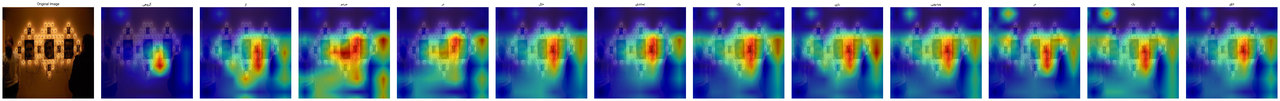

----------------------------------------
Displaying image with average BLEU of 0.000
Real Caption: مردی خوش‌لباس که مشغول <unk> با نوشیدنی است
Generated Caption: گروهی از مردم در حال تماشای تلویزیون در یک اتاق


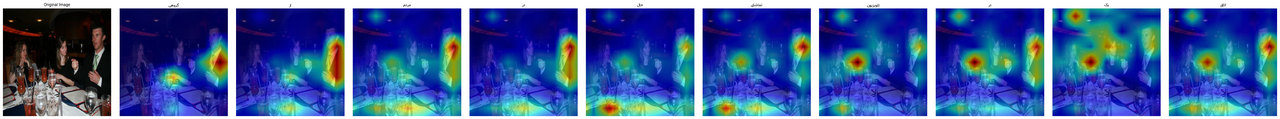

----------------------------------------
Displaying image with average BLEU of 0.000
Real Caption: خانمی که روی مقداری شن ایستاده_است
Generated Caption: مردی با لباس خیس در ساحل می‌دود


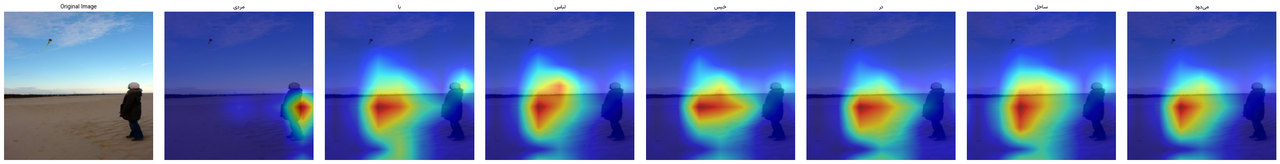

----------------------------------------
Displaying image with average BLEU of 0.000
Real Caption: خشک کردن گل رز
Generated Caption: گروهی از مردم در حال تماشای یک <unk>


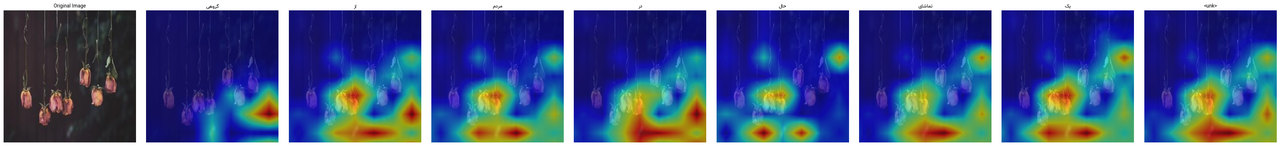

----------------------------------------
Displaying image with average BLEU of 0.000
Real Caption: دختران جوان با بچه <unk> روی نیمکت چوبی می‌نشینند
Generated Caption: عکس سیاه و سفید از یک قلعه در حال تماشای تلویزیون


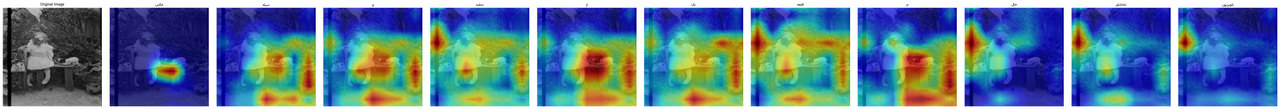

In [62]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
from nltk.translate.bleu_score import sentence_bleu,SmoothingFunction
from tqdm import tqdm
from PIL import Image
from skimage.transform import resize
import torch.nn as nn
import arabic_reshaper
from bidi.algorithm import get_display


def greedy_search_caption(model,image_tensor,vocab,device):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        for _ in range(30):
            embeds=model_to_use.decoder.embedding(input_word)
            context,_=model_to_use.decoder.attention(features,h)
            lstm_input=torch.cat((embeds,context),dim=1)
            h,c=model_to_use.decoder.decode_step(lstm_input,(h,c))
            output=model_to_use.decoder.fc(h)
            pred_idx=output.argmax(1)
            result_caption.append(pred_idx.item())
            if pred_idx.item()==vocab.stoi['<eos>']: break
            input_word=pred_idx
        return [vocab.itos[idx] for idx in result_caption if idx not in [0,1,2]]

def generate_caption_with_attention(model,image_tensor,vocab,device):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor.to(device))
        h,c=model_to_use.decoder.init_hidden_state(features)
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        attention_weights=[]
        for _ in range(30):
            embeds=model_to_use.decoder.embedding(input_word)
            context,alpha=model_to_use.decoder.attention(features,h)
            attention_weights.append(alpha.cpu())
            lstm_input=torch.cat((embeds,context),dim=1)
            h,c=model_to_use.decoder.decode_step(lstm_input,(h,c))
            output=model_to_use.decoder.fc(h)
            pred_idx=output.argmax(1)
            word_idx=pred_idx.item()
            result_caption.append(word_idx)
            if word_idx==vocab.stoi['<eos>']: break
            input_word=pred_idx
        caption_words=[vocab.itos[idx] for idx in result_caption if idx not in [0,1,2]]
        return caption_words,attention_weights

def beam_search_caption(model,image_tensor,vocab,device,beam_width=3):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        k_sequences=[([vocab.stoi['<sos>']],0.0,h,c)]
        for _ in range(30):
            all_candidates=[]
            for seq,score,h_prev,c_prev in k_sequences:
                if seq[-1]==vocab.stoi['<eos>']:
                    all_candidates.append((seq,score,h_prev,c_prev))
                    continue
                input_word=torch.tensor([seq[-1]]).to(device)
                embeds=model_to_use.decoder.embedding(input_word)
                context,_=model_to_use.decoder.attention(features,h_prev)
                lstm_input=torch.cat((embeds,context),dim=1)
                h_next,c_next=model_to_use.decoder.decode_step(lstm_input,(h_prev,c_prev))
                output=model_to_use.decoder.fc(h_next)
                log_probs=torch.nn.functional.log_softmax(output,dim=1)
                top_log_probs,top_indices=log_probs.topk(beam_width,dim=1)
                for i in range(beam_width):
                    next_word_idx=top_indices[0][i].item()
                    new_score=score+top_log_probs[0][i].item()
                    new_seq=seq+[next_word_idx]
                    all_candidates.append((new_seq,new_score,h_next,c_next))
            ordered=sorted(all_candidates,key=lambda x:x[1],reverse=True)
            k_sequences=ordered[:beam_width]
            if all(s[0][-1]==vocab.stoi['<eos>'] for s in k_sequences): break
        best_seq_indices=k_sequences[0][0]
        return [vocab.itos[idx] for idx in best_seq_indices if idx not in [0,1,2]]


print("--- Finding the worst performing examples based on average BLEU score... ---")
results=[]
chencherry=SmoothingFunction()
for i in tqdm(range(len(test_dataset)),desc="Evaluating Test Set"):
    image_tensor,caption_true_indices,_=test_dataset[i]
    model_input=image_tensor.unsqueeze(0).to(DEVICE)
    real_caption_words=[vocab.itos[idx.item()] for idx in caption_true_indices if idx.item() not in [0,1,2]]
    greedy_words=greedy_search_caption(model,model_input,vocab,DEVICE)
    beam_words=beam_search_caption(model,model_input,vocab,DEVICE,beam_width=3)
    reference=[real_caption_words]
    b1_g=sentence_bleu(reference,greedy_words,weights=(1,0,0,0))
    b4_g=sentence_bleu(reference,greedy_words,weights=(0.25,0.25,0.25,0.25),smoothing_function=chencherry.method1)
    b1_b=sentence_bleu(reference,beam_words,weights=(1,0,0,0))
    b4_b=sentence_bleu(reference,beam_words,weights=(0.25,0.25,0.25,0.25),smoothing_function=chencherry.method1)
    average_bleu=(b1_g+b4_g+b1_b+b4_b)/4.0
    results.append((average_bleu,image_tensor,real_caption_words))
results.sort(key=lambda x:x[0])
worst_samples=results[:5]
print("--- Found 5 examples. Now visualizing attention... ---")


for avg_score,image_tensor,real_caption_words in worst_samples:
    print("-" * 40)
    real_caption=' '.join(real_caption_words)
    print(f"Displaying image with average BLEU of {avg_score:.3f}")
    print(f"Real Caption: {real_caption}")
    
    model_input=image_tensor.unsqueeze(0).to(DEVICE)
    generated_words,attention_weights=generate_caption_with_attention(model,model_input,vocab,DEVICE)
    print(f"Generated Caption: {' '.join(generated_words)}")
    
    num_words=len(generated_words)
    if num_words==0: continue
        
    image_for_plot=image_tensor.permute(1,2,0).cpu().numpy()
    
    fig,axes=plt.subplots(1,num_words+1,figsize=((num_words+1)*4,4))
    
    original_title=get_display(arabic_reshaper.reshape("Original Image"))
    axes[0].imshow(image_for_plot)
    axes[0].set_title(original_title,fontproperties=persian_font)
    axes[0].axis('off')
        
    for i,word in enumerate(generated_words):
        ax=axes[i+1] 
        attention_map=attention_weights[i].squeeze(0).reshape(7,7)
        attention_heatmap=resize(attention_map.numpy(),(image_for_plot.shape[0],image_for_plot.shape[1]))
        ax.imshow(image_for_plot)
        ax.imshow(attention_heatmap,cmap='jet',alpha=0.6)
        ax.axis('off')
        word_disp=get_display(arabic_reshaper.reshape(word))
        ax.set_title(word_disp,fontproperties=persian_font)
        
    plt.tight_layout()
    plt.show()

In [9]:
import torch
import torch.nn as nn
import torchvision.models as models


class Encoder(nn.Module):
    def __init__(self,train_cnn=False):
        super(Encoder,self).__init__()
        efficientnet=models.efficientnet_b7(weights=models.EfficientNet_B7_Weights.DEFAULT)
        self.features=efficientnet.features
        if not train_cnn:
            for param in self.features.parameters():
                param.requires_grad=False
    def forward(self,images):
        features=self.features(images)
        batch_size,channels,height,width=features.size()
        features=features.view(batch_size,channels,-1).permute(0,2,1)
        return features

class Attention(nn.Module):
    def __init__(self,encoder_dim,decoder_dim,attention_dim):
        super(Attention,self).__init__()
        self.encoder_att=nn.Linear(encoder_dim,attention_dim)
        self.decoder_att=nn.Linear(decoder_dim,attention_dim)
        self.full_att=nn.Linear(attention_dim,1)
        self.relu=nn.ReLU()
        self.softmax=nn.Softmax(dim=1)
    def forward(self,encoder_out,decoder_hidden):
        att1=self.encoder_att(encoder_out)
        att2=self.decoder_att(decoder_hidden)
        combined_att=self.relu(att1+att2.unsqueeze(1))
        att_scores=self.full_att(combined_att).squeeze(2)
        alpha=self.softmax(att_scores)
        context_vector=(encoder_out*alpha.unsqueeze(2)).sum(dim=1)
        return context_vector,alpha

class Decoder(nn.Module):
    def __init__(self,embed_dim,decoder_dim,vocab_size,encoder_dim=2560,dropout=0.5):
        super(Decoder,self).__init__()
        self.attention=Attention(encoder_dim,decoder_dim,decoder_dim)
        self.embedding=nn.Embedding(vocab_size,embed_dim)
        self.dropout=nn.Dropout(p=dropout)
        self.decode_step=nn.LSTMCell(embed_dim+encoder_dim,decoder_dim,bias=True)
        self.init_h=nn.Linear(encoder_dim,decoder_dim)
        self.init_c=nn.Linear(encoder_dim,decoder_dim)
        self.fc=nn.Linear(decoder_dim,vocab_size)
    def init_hidden_state(self,encoder_out):
        mean_encoder_out=encoder_out.mean(dim=1)
        h=self.init_h(mean_encoder_out)
        c=self.init_c(mean_encoder_out)
        return h,c
    
    def forward(self,encoder_out,encoded_captions,caption_lengths,use_teacher_forcing):
        batch_size=encoder_out.size(0)
        vocab_size=self.fc.out_features
        decode_lengths=[l-1 for l in caption_lengths]
        predictions=torch.zeros(batch_size,max(decode_lengths),vocab_size).to(encoder_out.device)
        h,c=self.init_hidden_state(encoder_out)
        
        predictions=torch.zeros(batch_size,max(decode_lengths),vocab_size).to(encoder_out.device)
        input_word_indices=encoded_captions[:,0] 
        
        for t in range(max(decode_lengths)):
            batch_size_t=sum([l>t for l in decode_lengths])
            embeddings=self.embedding(input_word_indices[:batch_size_t])
            context_vector,_=self.attention(encoder_out[:batch_size_t],h[:batch_size_t])
            lstm_input=torch.cat((embeddings,context_vector),dim=1)
            h,c=self.decode_step(lstm_input,(h[:batch_size_t],c[:batch_size_t]))
            preds=self.fc(self.dropout(h))
            predictions[:batch_size_t,t,:]=preds
            
            if use_teacher_forcing:
                input_word_indices=encoded_captions[:batch_size_t,t+1]
            else:
                input_word_indices=preds.argmax(dim=1)
        return predictions

class ImageCaptioningModel(nn.Module):
    def __init__(self,embed_dim,decoder_dim,vocab_size,encoder_dim=2560,dropout=0.5):
        super(ImageCaptioningModel,self).__init__()
        self.encoder=Encoder()
        self.decoder=Decoder(embed_dim,decoder_dim,vocab_size,encoder_dim,dropout)
        
    # --- CHANGE: forward method passes the boolean to the decoder ---
    def forward(self,images,captions,caption_lengths,use_teacher_forcing):
        encoder_out=self.encoder(images)
        outputs=self.decoder(encoder_out,captions,caption_lengths,use_teacher_forcing)
        return outputs


embed_dim=512
decoder_dim=512
vocab_size=3192
dropout=0.5

model_ss=ImageCaptioningModel(embed_dim=embed_dim,decoder_dim=decoder_dim,vocab_size=vocab_size,dropout=dropout)
print("--- 'Scheduled model' architecture is defined and instantiated as 'model_ss' ---")

--- 'Scheduled model' architecture is defined and instantiated as 'model_ss' ---


Using device: cuda
Model, Loss, Optimizer, and LR Scheduler are ready.

--- Starting Training for Scheduled Model ---


Epoch 1/20 -> Train Loss: 5.3267, Val Loss: 4.7808


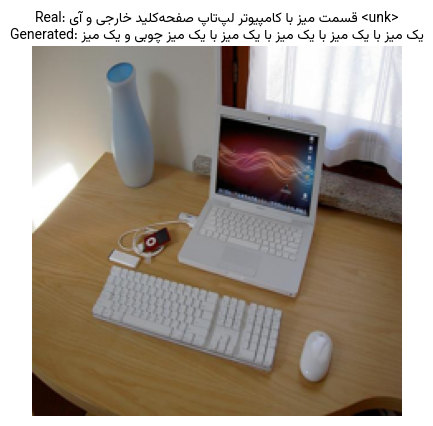

Epoch 2/20 -> Train Loss: 4.6698, Val Loss: 4.4635


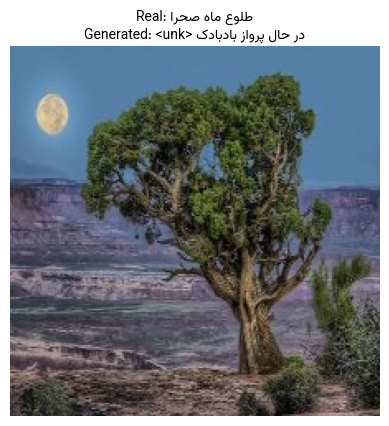

Epoch 3/20 -> Train Loss: 4.4450, Val Loss: 4.3135


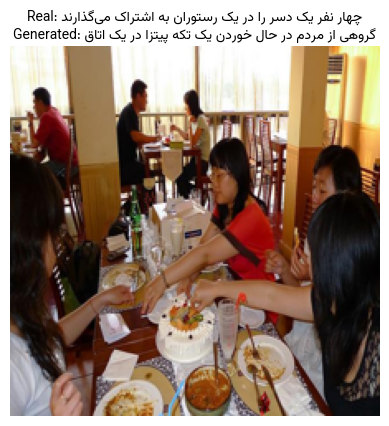

Epoch 4/20 -> Train Loss: 4.3272, Val Loss: 4.2316


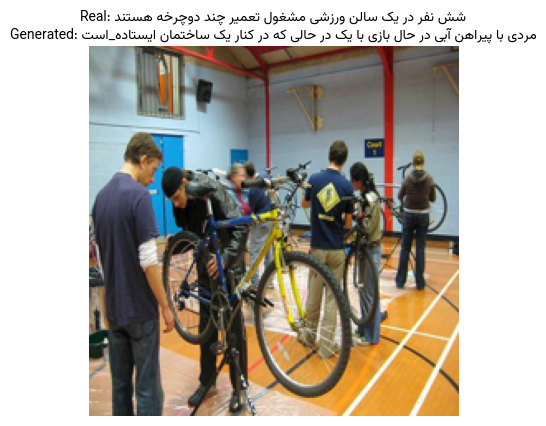

Epoch 5/20 -> Train Loss: 4.1901, Val Loss: 4.1704


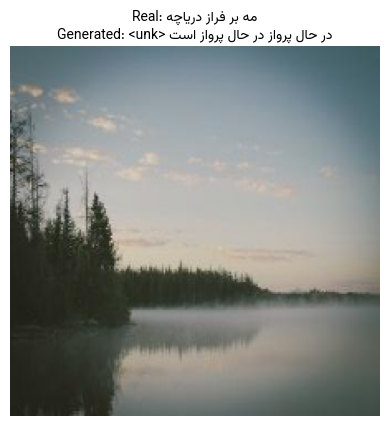

Epoch 6/20 -> Train Loss: 4.1151, Val Loss: 4.1442


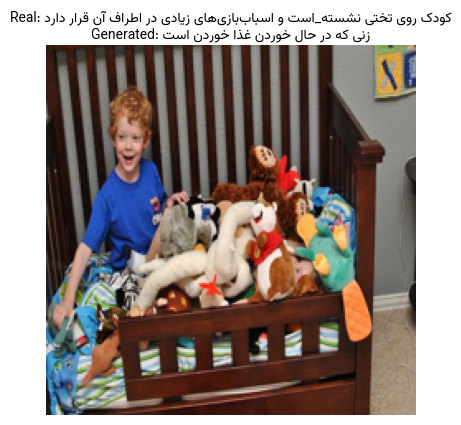

Epoch 7/20 -> Train Loss: 4.0787, Val Loss: 4.1248


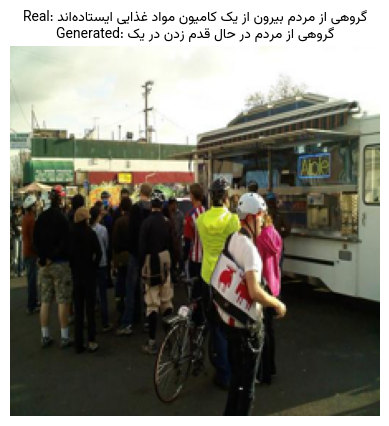

Epoch 8/20 -> Train Loss: 4.0459, Val Loss: 4.1227


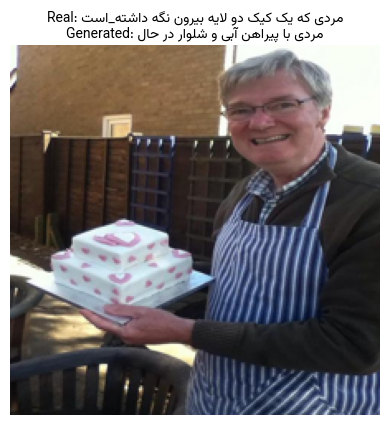

Epoch 9/20 -> Train Loss: 4.0664, Val Loss: 4.1374


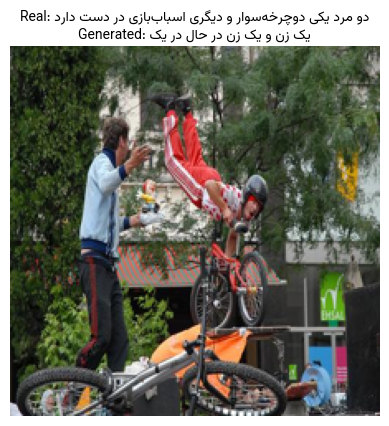

Epoch 10/20 -> Train Loss: 4.0767, Val Loss: 4.1260


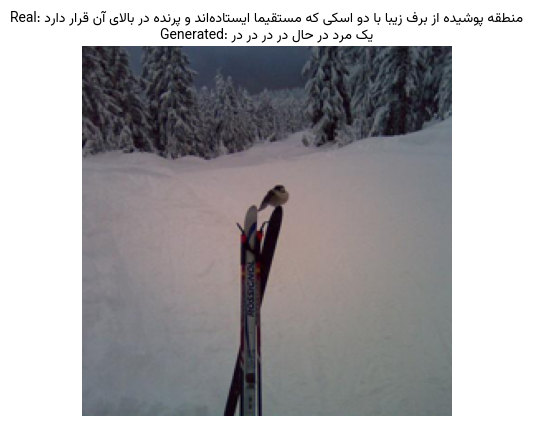

Epoch 11/20 -> Train Loss: 3.9374, Val Loss: 4.1189


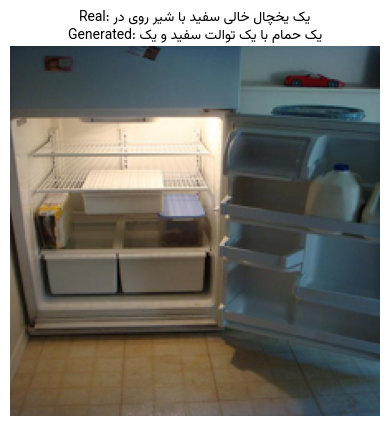

Epoch 12/20 -> Train Loss: 3.9802, Val Loss: 4.1356


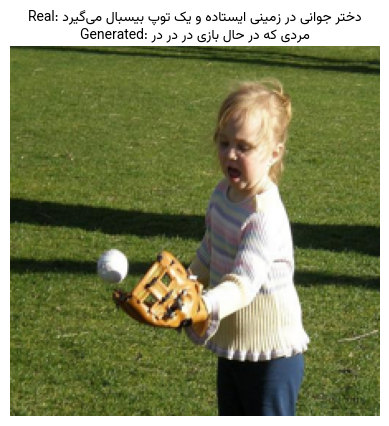

Epoch 13/20 -> Train Loss: 3.9729, Val Loss: 4.1475


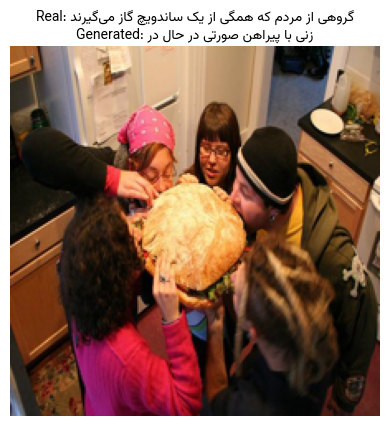

Epoch 14/20 -> Train Loss: 3.9610, Val Loss: 4.1619


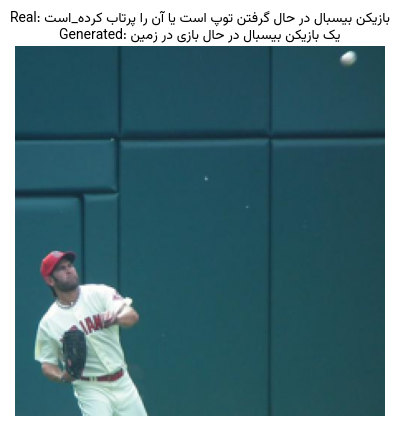

Epoch 15/20 -> Train Loss: 3.9332, Val Loss: 4.1478


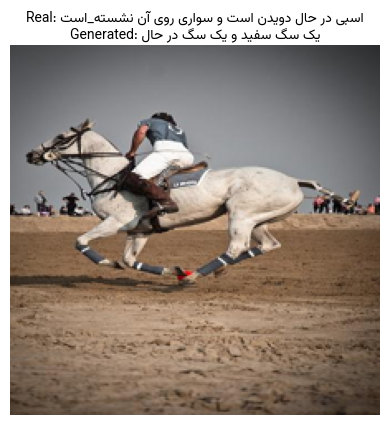

Epoch 16/20 -> Train Loss: 3.9731, Val Loss: 4.1602


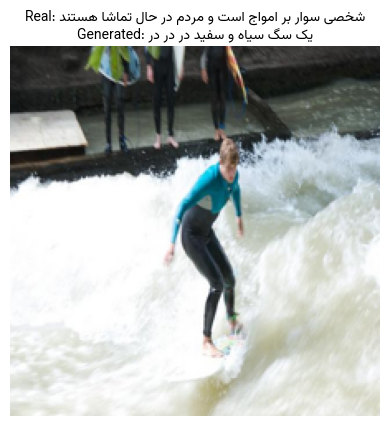

Epoch 17/20 -> Train Loss: 3.9941, Val Loss: 4.1585


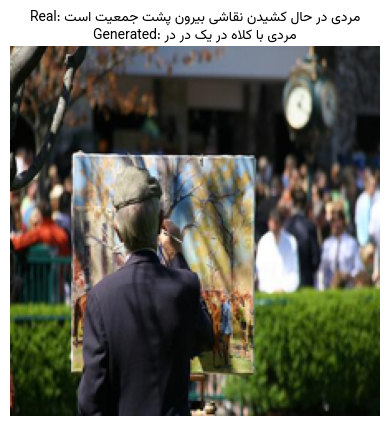

Epoch 18/20 -> Train Loss: 4.0796, Val Loss: 4.1648


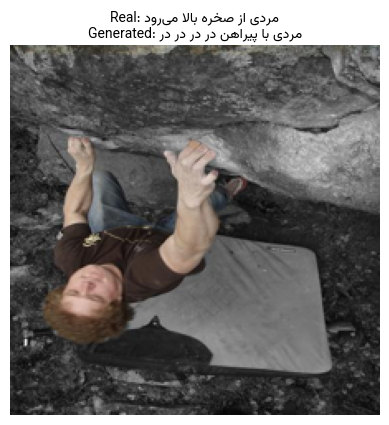

Epoch 19/20 -> Train Loss: 4.0468, Val Loss: 4.1655


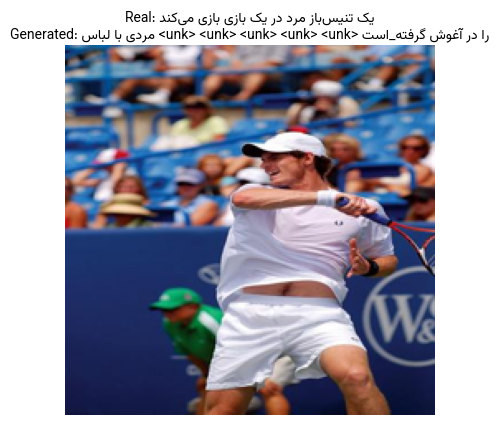

Epoch 20/20 -> Train Loss: 4.0785, Val Loss: 4.1663


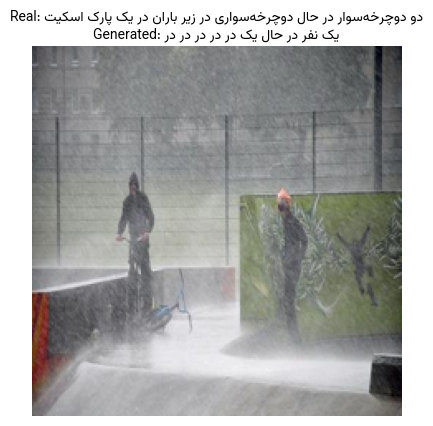

--- Training Complete: Plotting Loss Curves for Scheduled Model ---


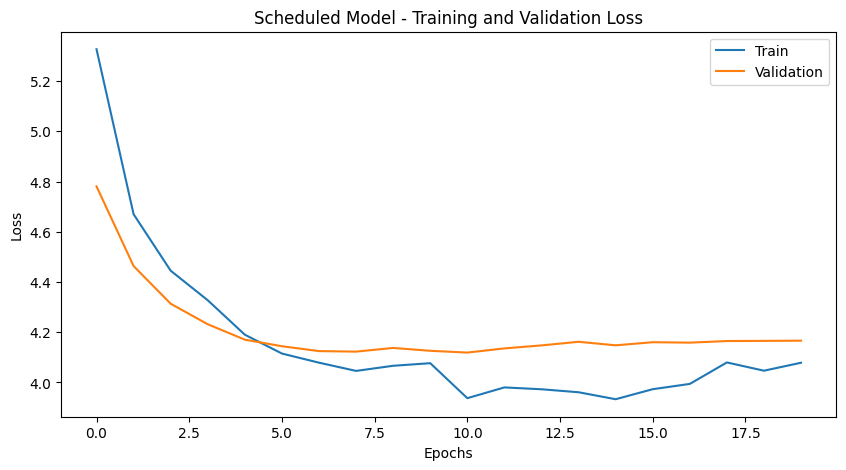

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display
import random
from matplotlib.font_manager import FontProperties

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

vocab_size=len(vocab)
embed_dim=512
decoder_dim=512
encoder_dim=2560
dropout=0.5

epochs=20
learning_rate=5e-4
weight_decay=1e-4
grad_clip=5.0

if torch.cuda.device_count()>1:
    print(f"--- Using {torch.cuda.device_count()} GPUs! ---")
    model_ss=nn.DataParallel(model_ss)

model_ss.to(device)

criterion=nn.CrossEntropyLoss(ignore_index=vocab.stoi["<pad>"])
optimizer=torch.optim.AdamW(model_ss.parameters(),lr=learning_rate,weight_decay=weight_decay)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.1,patience=2,verbose=True)
print("Model, Loss, Optimizer, and LR Scheduler are ready.")


def generate_example_caption(model,dataset,vocab):
    model.eval()
    with torch.no_grad():
        idx = random.randint(0,len(dataset)-1)
        image, caption_true, _=dataset[idx]
        image_for_model = image.unsqueeze(0).to(device)
        real_caption = ' '.join([vocab.itos[idx.item()] for idx in caption_true if idx.item() not in [0, 1, 2]])
        
        model_to_use = model.module if isinstance(model, nn.DataParallel) else model
        
        features = model_to_use.encoder(image_for_model)
        h, c = model_to_use.decoder.init_hidden_state(features)
        
        input_word = torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption = []
        for _ in range(30):
            embeddings = model_to_use.decoder.embedding(input_word)
            context_vector, _ = model_to_use.decoder.attention(features, h)
            lstm_input = torch.cat((embeddings, context_vector), dim=1)
            h, c = model_to_use.decoder.decode_step(lstm_input, (h, c))
            output = model_to_use.decoder.fc(h)
            predicted_word_idx = output.argmax(1)
            result_caption.append(predicted_word_idx.item())
            if predicted_word_idx.item() == vocab.stoi['<eos>']: break
            input_word = predicted_word_idx
            
        generated_caption = ' '.join([vocab.itos[idx] for idx in result_caption if idx not in [0, 1, 2]])
        image_for_plot = image.permute(1, 2, 0).cpu().numpy()
        plt.imshow(image_for_plot)
        real_caption_display = get_display(arabic_reshaper.reshape(f"Real: {real_caption}"))
        gen_caption_display = get_display(arabic_reshaper.reshape(f"Generated: {generated_caption}"))
        plt.title(f"{real_caption_display}\n{gen_caption_display}",fontproperties=persian_font)
        plt.axis('off')
        plt.show()
    model.train()


train_losses_ss=[]
val_losses_ss=[]
print("\n--- Starting Training for Scheduled Model ---")

for epoch in range(epochs):
    model_ss.train()
    
    p=max(0.5,1.0-((1.0-0.5)/epochs)*epoch)
    
    loop=tqdm(train_loader,total=len(train_loader),leave=False)
    loop.set_description(f"Epoch [{epoch+1}/{epochs}] Training (p={p:.2f})")
    total_loss_train=0
    
    for images,captions,caption_lengths in loop:
        images,captions=images.to(device),captions.to(device)
        
        use_teacher_forcing=(random.random()<p)
        
        outputs=model_ss(images,captions,caption_lengths.cpu().tolist(),use_teacher_forcing)
        
        targets=captions[:,1:]
        loss=criterion(outputs.reshape(-1,vocab_size),targets.reshape(-1))
        
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_ss.parameters(),grad_clip)
        optimizer.step()
        
        total_loss_train+=loss.item()
        loop.set_postfix(loss=loss.item())
        
    train_losses_ss.append(total_loss_train/len(train_loader))
    
    model_ss.eval()
    total_loss_val=0
    with torch.no_grad():
        for images,captions,caption_lengths in val_loader:
            images,captions=images.to(device),captions.to(device)
            outputs=model_ss(images,captions,caption_lengths.cpu().tolist(),use_teacher_forcing=True)
            targets=captions[:,1:]
            loss_val=criterion(outputs.reshape(-1,vocab_size),targets.reshape(-1))
            total_loss_val+=loss_val.item()
            
    val_losses_ss.append(total_loss_val/len(val_loader))
    
    scheduler.step(val_losses_ss[-1])
    
    print(f"\nEpoch {epoch+1}/{epochs} -> Train Loss: {train_losses_ss[-1]:.4f}, Val Loss: {val_losses_ss[-1]:.4f}")
    
    generate_example_caption(model_ss,val_dataset,vocab)


print("\n--- Training Complete: Plotting Loss Curves for Scheduled Model ---")
plt.figure(figsize=(10,5))
plt.title("Scheduled Model - Training and Validation Loss")
plt.plot(train_losses_ss,label="Train")
plt.plot(val_losses_ss,label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [12]:
import torch
import numpy as np
from nltk.translate.bleu_score import corpus_bleu,SmoothingFunction
from tqdm import tqdm
import torch.nn as nn


def greedy_search_caption(model,image_tensor,vocab,device):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        for _ in range(30):
            embeddings=model_to_use.decoder.embedding(input_word)
            context, _=model_to_use.decoder.attention(features,h)
            lstm_input=torch.cat((embeddings,context),dim=1)
            h,c=model_to_use.decoder.decode_step(lstm_input,(h,c))
            output=model_to_use.decoder.fc(h)
            pred_idx=output.argmax(1)
            result_caption.append(pred_idx.item())
            if pred_idx.item()==vocab.stoi['<eos>']: break
            input_word=pred_idx
        return [vocab.itos[idx] for idx in result_caption if idx not in [0, 1, 2]]

def beam_search_caption(model,image_tensor,vocab,device,beam_width=3):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        k_sequences=[([vocab.stoi['<sos>']], 0.0,h,c)]
        for _ in range(30):
            all_candidates=[]
            for seq,score,h_prev,c_prev in k_sequences:
                if seq[-1] == vocab.stoi['<eos>']:
                    all_candidates.append((seq,score,h_prev,c_prev))
                    continue
                input_word=torch.tensor([seq[-1]]).to(device)
                embeddings=model_to_use.decoder.embedding(input_word)
                context, _=model_to_use.decoder.attention(features,h_prev)
                lstm_input=torch.cat((embeddings,context),dim=1)
                h_next,c_next=model_to_use.decoder.decode_step(lstm_input,(h_prev,c_prev))
                output=model_to_use.decoder.fc(h_next)
                log_probs=torch.nn.functional.log_softmax(output,dim=1)
                top_log_probs,top_indices=log_probs.topk(beam_width,dim=1)
                for i in range(beam_width):
                    next_word_idx=top_indices[0][i].item()
                    new_score=score+top_log_probs[0][i].item()
                    new_seq=seq+[next_word_idx]
                    all_candidates.append((new_seq,new_score,h_next,c_next))
            ordered=sorted(all_candidates,key=lambda x: x[1],reverse=True)
            k_sequences=ordered[:beam_width]
            if all(s[0][-1] == vocab.stoi['<eos>'] for s in k_sequences): break
        best_seq_indices=k_sequences[0][0]
        return [vocab.itos[idx] for idx in best_seq_indices if idx not in [0, 1, 2]]

print("\n--- Evaluating Scheduled Sampling Model on the Entire Test Set ---")
model_ss.eval()
greedy_hypotheses=[]
beam_hypotheses=[]
all_references=[]
chencherry=SmoothingFunction()

with torch.no_grad():
    for images,captions, _ in tqdm(test_loader,desc="Evaluating Test Set"):
        images=images.to(device)
        for i in range(images.size(0)):
            image_tensor=images[i].unsqueeze(0)
            
            real_caption_indices=captions[i]
            real_caption_words=[vocab.itos[idx.item()] for idx in real_caption_indices if idx.item() not in [0, 1, 2]]
            all_references.append([real_caption_words])
            
            greedy_hypotheses.append(greedy_search_caption(model_ss,image_tensor,vocab,device))
            beam_hypotheses.append(beam_search_caption(model_ss,image_tensor,vocab,device,beam_width=3))

bleu1_greedy_corpus=corpus_bleu(all_references,greedy_hypotheses,weights=(1,0,0,0))
bleu4_greedy_corpus=corpus_bleu(all_references,greedy_hypotheses,weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=chencherry.method1)
bleu1_beam_corpus=corpus_bleu(all_references,beam_hypotheses,weights=(1, 0, 0, 0))
bleu4_beam_corpus=corpus_bleu(all_references,beam_hypotheses,weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=chencherry.method1)

print("\n--- Scheduled Sampling Model: Overall Test Set BLEU Scores ---")
print(f"Greedy Search -> BLEU-1: {bleu1_greedy_corpus:.4f} | BLEU-4: {bleu4_greedy_corpus:.4f}")
print(f"Beam Search (k=3) -> BLEU-1: {bleu1_beam_corpus:.4f} | BLEU-4: {bleu4_beam_corpus:.4f}")


--- Evaluating Scheduled Sampling Model on the Entire Test Set ---


Evaluating Test Set: 100%|██████████| 63/63 [02:53<00:00,  2.76s/it]


--- Scheduled Sampling Model: Overall Test Set BLEU Scores ---
Greedy Search -> BLEU-1: 0.1924 | BLEU-4: 0.0270
Beam Search (k=3) -> BLEU-1: 0.1883 | BLEU-4: 0.0320


In [14]:
import torch
import torch.nn as nn
import torchvision.models as models
import math


class Encoder(nn.Module):

    def __init__(self,train_cnn=False):
        super(Encoder,self).__init__()
        efficientnet=models.efficientnet_b7(weights=models.EfficientNet_B7_Weights.DEFAULT)
        
        self.features=efficientnet.features
        self.avgpool=efficientnet.avgpool
        
        if not train_cnn:
            for param in self.features.parameters():
                param.requires_grad=False

    def forward(self,images):
        features=self.features(images) 
        
        batch_size,channels,height,width=features.size()
        features=features.view(batch_size,channels,-1)
        features=features.permute(0,2,1)
        return features


class ScaledDotProductAttention(nn.Module):

    def __init__(self,encoder_dim,decoder_dim):
        super(ScaledDotProductAttention,self).__init__()

        self.query_proj=nn.Linear(decoder_dim,decoder_dim)
        self.key_proj=nn.Linear(encoder_dim,decoder_dim)
        self.value_proj=nn.Linear(encoder_dim,decoder_dim)

        self.softmax=nn.Softmax(dim=-1)
        self.scale=1. / math.sqrt(decoder_dim)

    def forward(self,encoder_out,decoder_hidden):
        query=self.query_proj(decoder_hidden).unsqueeze(1)
        keys=self.key_proj(encoder_out)
        values=self.value_proj(encoder_out)

        scores=torch.matmul(query,keys.transpose(1, 2))
        scaled_scores=scores*self.scale
        alpha=self.softmax(scaled_scores)
        context_vector=torch.matmul(alpha,values)
        
        return context_vector.squeeze(1), alpha.squeeze(1)


class Decoder_DotProduct(nn.Module):
    def __init__(self,embed_dim,decoder_dim,vocab_size,encoder_dim=2560,dropout=0.5):
        super(Decoder_DotProduct, self).__init__()
        self.attention=ScaledDotProductAttention(encoder_dim,decoder_dim)
        self.embedding=nn.Embedding(vocab_size,embed_dim)
        self.dropout=nn.Dropout(p=dropout)
        self.decode_step=nn.LSTMCell(embed_dim+decoder_dim,decoder_dim,bias=True)
        self.init_h=nn.Linear(encoder_dim,decoder_dim)
        self.init_c=nn.Linear(encoder_dim,decoder_dim)
        self.fc=nn.Linear(decoder_dim,vocab_size)

    def init_hidden_state(self,encoder_out):
        mean_encoder_out=encoder_out.mean(dim=1)
        h=self.init_h(mean_encoder_out)
        c=self.init_c(mean_encoder_out)
        return h,c

    def forward(self,encoder_out,encoded_captions,caption_lengths):
        batch_size=encoder_out.size(0)
        vocab_size=self.fc.out_features
        embeddings=self.embedding(encoded_captions)
        h,c=self.init_hidden_state(encoder_out)
        decode_lengths=[l - 1 for l in caption_lengths]
        
        predictions=torch.zeros(batch_size,max(decode_lengths),vocab_size).to(encoder_out.device)

        for t in range(max(decode_lengths)):
            batch_size_t=sum([l > t for l in decode_lengths])
            context_vector, _=self.attention(encoder_out[:batch_size_t], h[:batch_size_t])
            lstm_input=torch.cat((embeddings[:batch_size_t, t, :], context_vector), dim=1)
            h,c=self.decode_step(lstm_input,(h[:batch_size_t], c[:batch_size_t]))
            preds=self.fc(self.dropout(h))
            predictions[:batch_size_t, t, :]=preds
            
        return predictions

class ImageCaptioningModel_DotProduct(nn.Module):
    def __init__(self,embed_dim,decoder_dim,vocab_size,encoder_dim=2560,dropout=0.5):
        super(ImageCaptioningModel_DotProduct,self).__init__()
        self.encoder=Encoder()
        self.decoder=Decoder_DotProduct(embed_dim,decoder_dim,vocab_size,encoder_dim,dropout)

    def forward(self,images,captions,caption_lengths):
        encoder_out=self.encoder(images)
        outputs=self.decoder(encoder_out,captions,caption_lengths)
        return outputs


embed_dim=512
decoder_dim=512
vocab_size=len(vocab)
dropout=0.5

model_dot_product=ImageCaptioningModel_DotProduct(
    embed_dim=embed_dim,
    decoder_dim=decoder_dim,
    vocab_size=vocab_size,
    dropout=dropout
)

print("--- 'model_dot_product' with Scaled Dot-Product Attention has been created. ---")


--- 'model_dot_product' with Scaled Dot-Product Attention has been created. ---


Using device: cuda
Model, Loss, Optimizer, and LR Scheduler are ready for the Dot-Product model.

--- Starting Training for Dot-Product Model (Effective Batch Size: 32) ---


Epoch 1/20 -> Train Loss: 2.8773, Val Loss: 5.1297


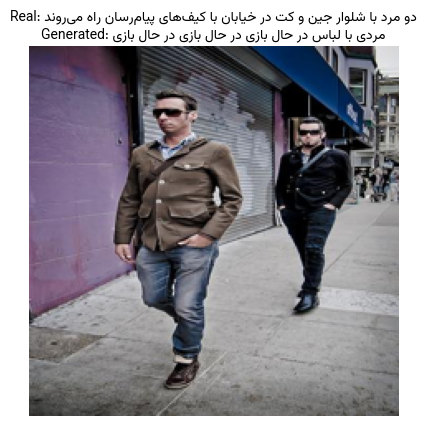

Epoch 2/20 -> Train Loss: 2.4552, Val Loss: 4.6657


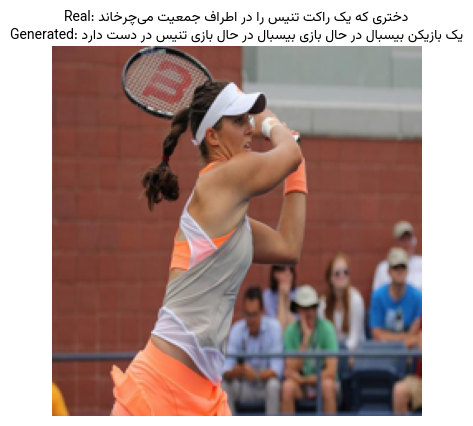

Epoch 3/20 -> Train Loss: 2.2741, Val Loss: 4.4337


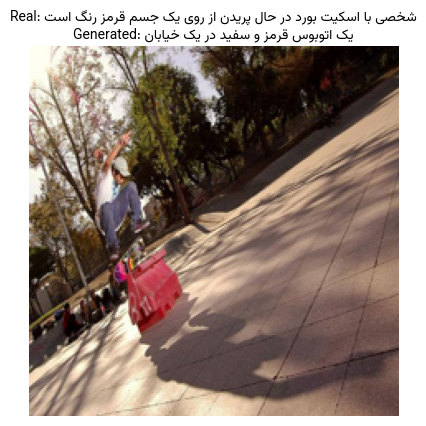

Epoch 4/20 -> Train Loss: 2.1662, Val Loss: 4.2969


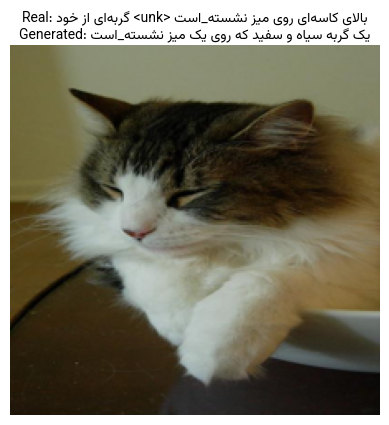

Epoch 5/20 -> Train Loss: 2.0857, Val Loss: 4.2105


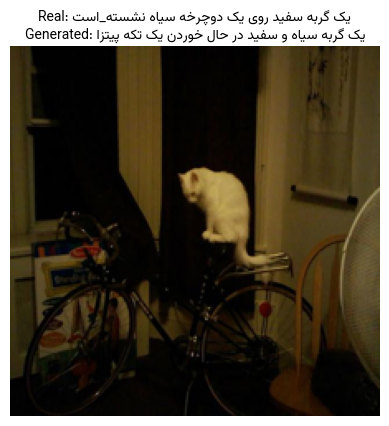

Epoch 6/20 -> Train Loss: 2.0196, Val Loss: 4.1505


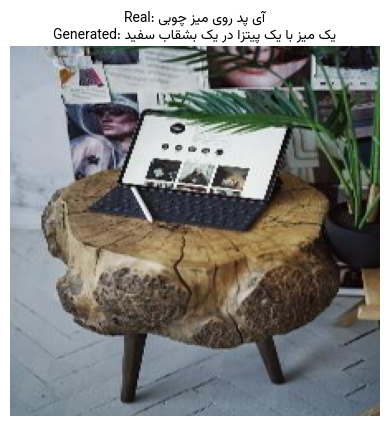

Epoch 7/20 -> Train Loss: 1.9656, Val Loss: 4.1109


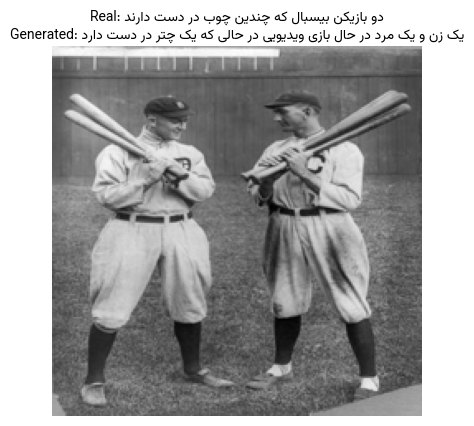

Epoch 8/20 -> Train Loss: 1.9160, Val Loss: 4.0776


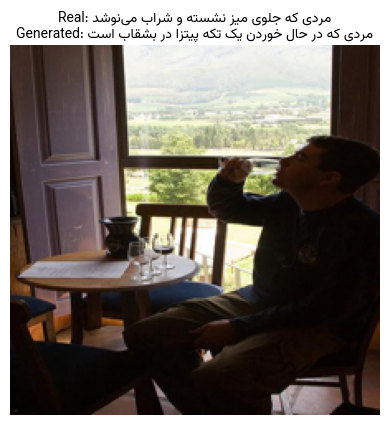

Epoch 9/20 -> Train Loss: 1.8709, Val Loss: 4.0561


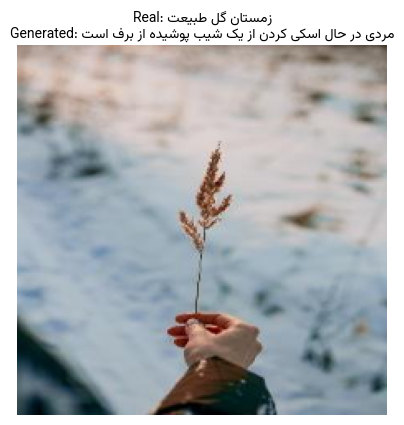

Epoch 10/20 -> Train Loss: 1.8294, Val Loss: 4.0415


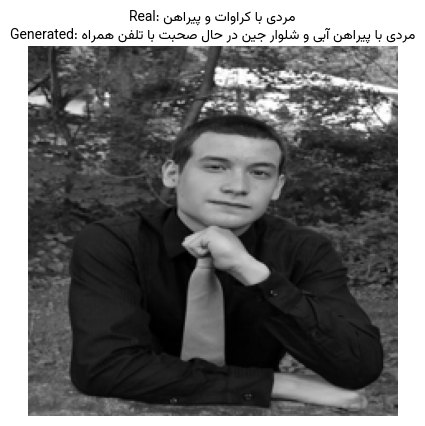

Epoch 11/20 -> Train Loss: 1.7908, Val Loss: 4.0316


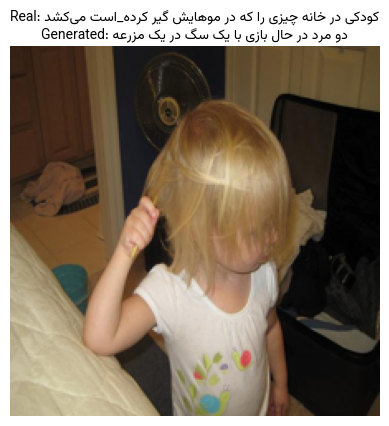

Epoch 12/20 -> Train Loss: 1.7513, Val Loss: 4.0311


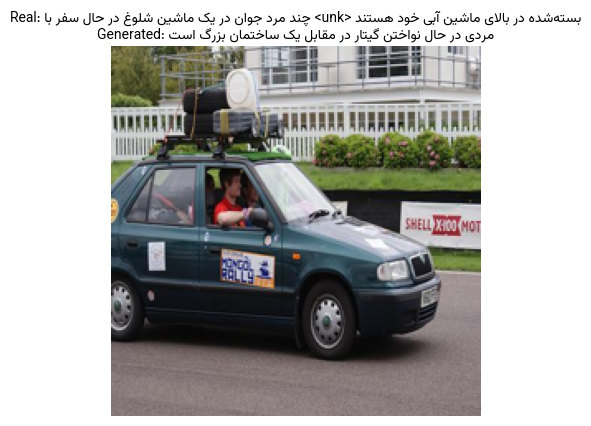

Epoch 13/20 -> Train Loss: 1.7249, Val Loss: 4.0315


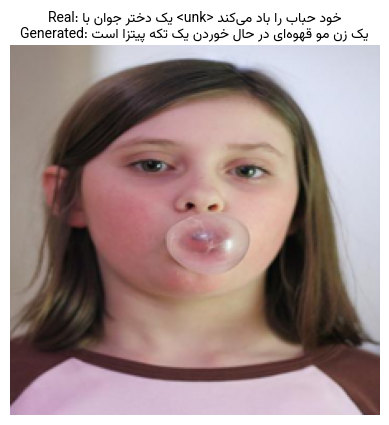

Epoch 14/20 -> Train Loss: 1.6862, Val Loss: 4.0269


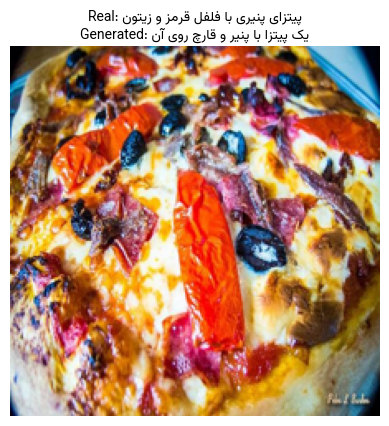

Epoch 15/20 -> Train Loss: 1.6555, Val Loss: 4.0398


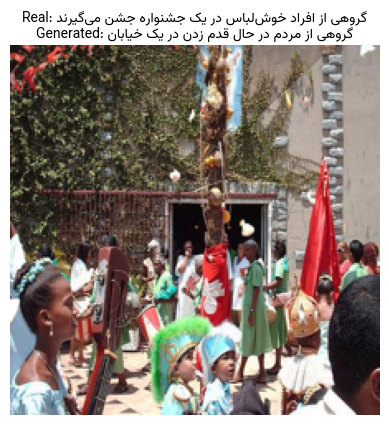

Epoch 16/20 -> Train Loss: 1.6250, Val Loss: 4.0410


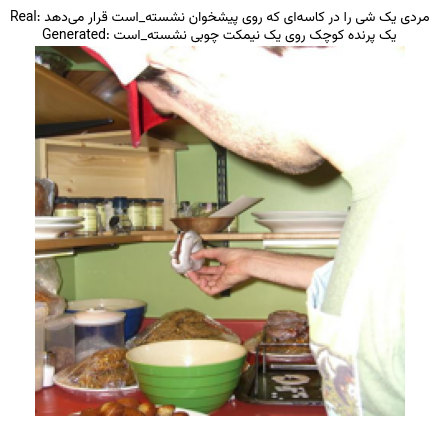

Epoch 17/20 -> Train Loss: 1.5945, Val Loss: 4.0524


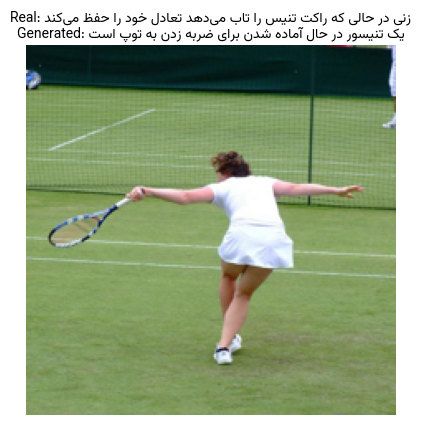

Epoch 18/20 -> Train Loss: 1.5363, Val Loss: 4.0475


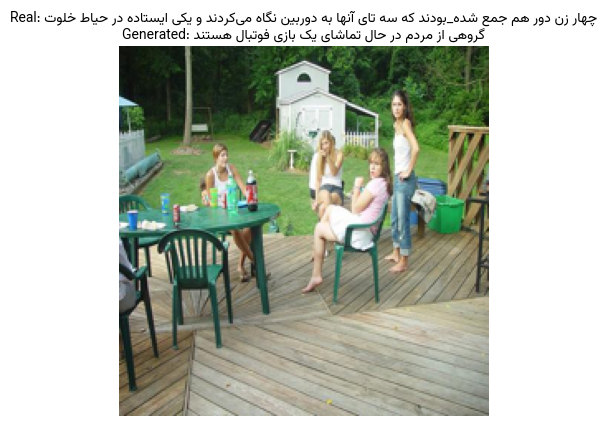

Epoch 19/20 -> Train Loss: 1.5234, Val Loss: 4.0487


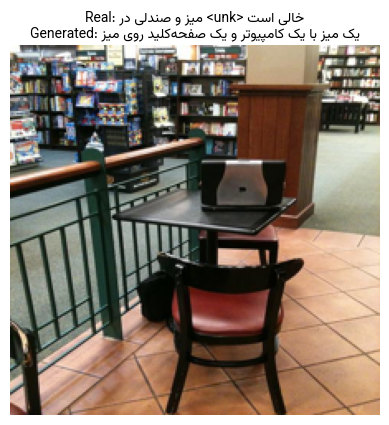

Epoch 20/20 -> Train Loss: 1.5162, Val Loss: 4.0506


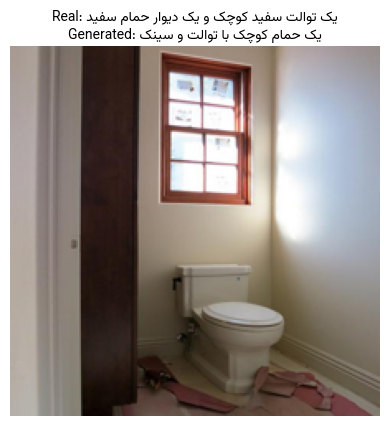

--- Training Complete: Plotting Loss Curves for Dot-Product Model ---


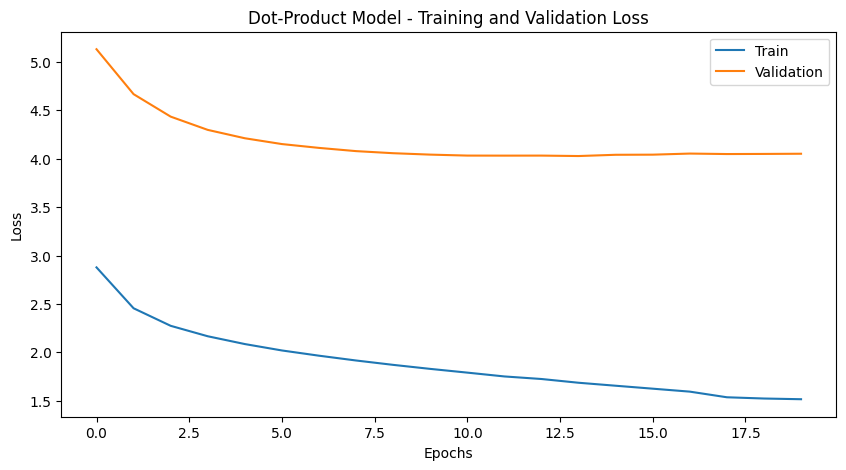

In [15]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display
import random
from matplotlib.font_manager import FontProperties


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

vocab_size=len(vocab)
embed_dim=512
decoder_dim=512
encoder_dim=2560
dropout=0.5


epochs= 20
BATCH_SIZE=16
ACCUMULATION_STEPS=2
learning_rate=5e-4
weight_decay=1e-4
grad_clip=5.0


if torch.cuda.device_count() > 1:
    print(f"--- Using {torch.cuda.device_count()} GPUs for Dot-Product Model! ---")
    model_dot_product = nn.DataParallel(model_dot_product)

model_dot_product.to(device)

criterion=nn.CrossEntropyLoss(ignore_index=vocab.stoi["<pad>"])
optimizer_dp=torch.optim.AdamW(filter(lambda p: p.requires_grad,model_dot_product.parameters()),lr=learning_rate,weight_decay=weight_decay)
scheduler_dp=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_dp,mode='min',factor=0.1,patience=2,verbose=True)
print("Model, Loss, Optimizer, and LR Scheduler are ready for the Dot-Product model.")

def generate_example_caption(model, dataset, vocab):
    model.eval()
    with torch.no_grad():
        idx=random.randint(0,len(dataset)-1)
        image,caption_true, _ =dataset[idx]
        image_for_model=image.unsqueeze(0).to(device)
        real_caption=' '.join([vocab.itos[idx.item()] for idx in caption_true if idx.item() not in [0, 1, 2]])
        
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        
        features=model_to_use.encoder(image_for_model)
        h,c=model_to_use.decoder.init_hidden_state(features)
        
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        for _ in range(30):
            embeddings=model_to_use.decoder.embedding(input_word)
            context_vector, _=model_to_use.decoder.attention(features, h)
            lstm_input=torch.cat((embeddings,context_vector),dim=1)
            h,c=model_to_use.decoder.decode_step(lstm_input,(h,c))
            output=model_to_use.decoder.fc(h)
            predicted_word_idx=output.argmax(1)
            result_caption.append(predicted_word_idx.item())
            if predicted_word_idx.item() == vocab.stoi['<eos>']: break
            input_word=predicted_word_idx
            
        generated_caption=' '.join([vocab.itos[idx] for idx in result_caption if idx not in [0, 1, 2]])
        image_for_plot=image.permute(1, 2, 0).cpu().numpy()
        plt.imshow(image_for_plot)
        real_caption_display=get_display(arabic_reshaper.reshape(f"Real: {real_caption}"))
        gen_caption_display=get_display(arabic_reshaper.reshape(f"Generated: {generated_caption}"))
        plt.title(f"{real_caption_display}\n{gen_caption_display}", fontproperties=persian_font)
        plt.axis('off')
        plt.show()
    model.train()

train_losses_dp = []
val_losses_dp = []
print(f"\n--- Starting Training for Dot-Product Model (Effective Batch Size: {BATCH_SIZE*ACCUMULATION_STEPS}) ---")

for epoch in range(epochs):
    model_dot_product.train()
    loop=tqdm(train_loader,total=len(train_loader),leave=False)
    loop.set_description(f"Epoch [{epoch+1}/{epochs}] Training")
    total_loss_train=0
    optimizer_dp.zero_grad()
    
    for i,(images,captions,caption_lengths) in enumerate(loop):
        images,captions=images.to(device),captions.to(device)
        
        outputs=model_dot_product(images,captions,caption_lengths.cpu().tolist())
        
        targets=captions[:,1:]
        loss=criterion(outputs.reshape(-1,vocab_size),targets.reshape(-1))
        loss=loss/ACCUMULATION_STEPS
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_dot_product.parameters(),grad_clip)
        
        if (i+1) % ACCUMULATION_STEPS == 0 or (i+1) == len(train_loader):
            optimizer_dp.step()
            optimizer_dp.zero_grad()
            
        total_loss_train += loss.item()
        loop.set_postfix(loss=loss.item()*ACCUMULATION_STEPS)
        
    train_losses_dp.append(total_loss_train / len(train_loader))
    
    model_dot_product.eval()
    total_loss_val=0
    with torch.no_grad():
        for images,captions,caption_lengths in val_loader:
            images,captions=images.to(device),captions.to(device)
            outputs=model_dot_product(images,captions,caption_lengths.cpu().tolist())
            targets=captions[:,1:]
            loss_val=criterion(outputs.reshape(-1,vocab_size), targets.reshape(-1))
            total_loss_val+=loss_val.item()
            
    val_losses_dp.append(total_loss_val / len(val_loader))
    scheduler_dp.step(val_losses_dp[-1])
    
    print(f"\nEpoch {epoch+1}/{epochs} -> Train Loss: {train_losses_dp[-1]:.4f}, Val Loss: {val_losses_dp[-1]:.4f}")
    generate_example_caption(model_dot_product, val_dataset, vocab)

print("\n--- Training Complete: Plotting Loss Curves for Dot-Product Model ---")
plt.figure(figsize=(10, 5))
plt.title("Dot-Product Model - Training and Validation Loss")
plt.plot(train_losses_dp, label="Train")
plt.plot(val_losses_dp, label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()


--- Evaluating Dot-Product Model on the Entire Test Set ---


Evaluating Dot-Product Model: 100%|██████████| 63/63 [03:08<00:00,  3.00s/it]


--- Dot-Product Model: Overall Test Set BLEU Scores ---
Greedy Search -> BLEU-1: 0.2268 | BLEU-4: 0.0380
Beam Search (k=3) -> BLEU-1: 0.2154 | BLEU-4: 0.0396

--- Generating and Evaluating 5 Random Test Images from Dot-Product Model ---


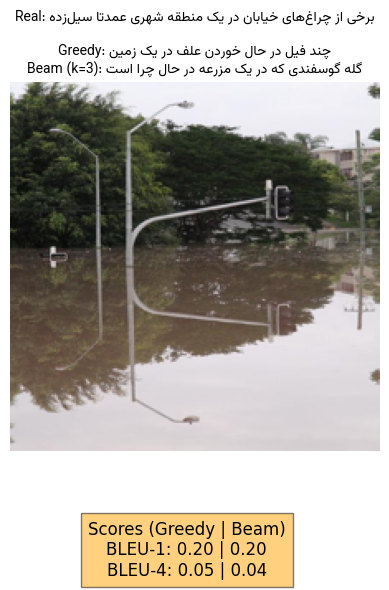

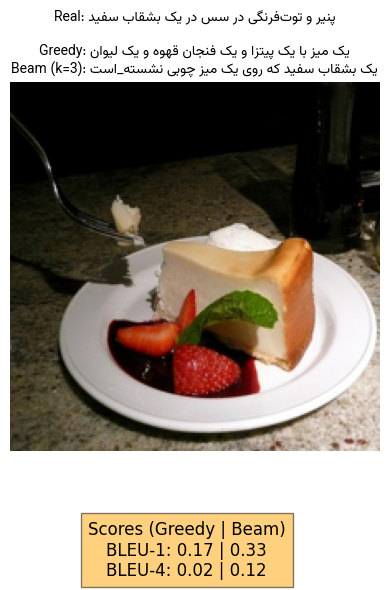

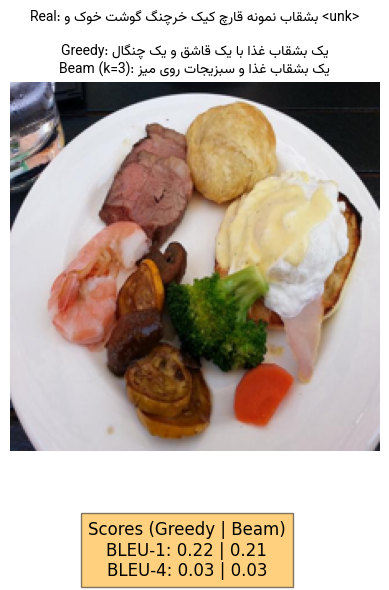

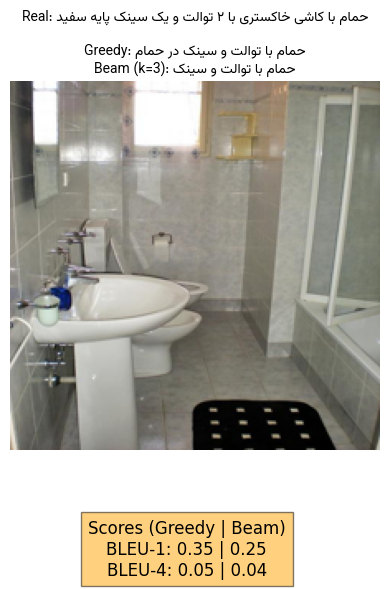

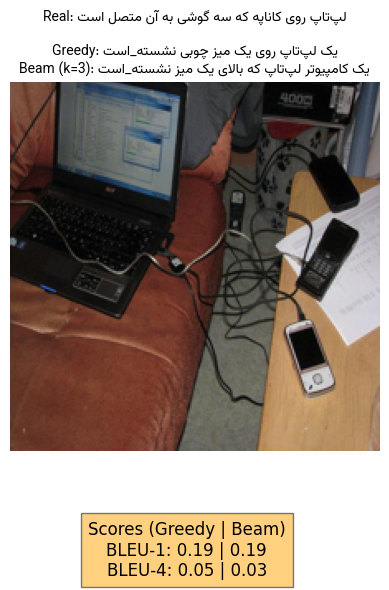

In [18]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
from nltk.translate.bleu_score import sentence_bleu,corpus_bleu,SmoothingFunction
from tqdm import tqdm
import torch.nn as nn



DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")

import arabic_reshaper
from bidi.algorithm import get_display


def greedy_search_caption(model,image_tensor,vocab,device):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        input_word=torch.tensor([vocab.stoi['<sos>']]).to(device)
        result_caption=[]
        for _ in range(30):
            embeddings=model_to_use.decoder.embedding(input_word)
            context,_=model_to_use.decoder.attention(features,h)
            lstm_input=torch.cat((embeddings,context),dim=1)
            h,c=model_to_use.decoder.decode_step(lstm_input,(h,c))
            output=model_to_use.decoder.fc(h)
            pred_idx=output.argmax(1)
            result_caption.append(pred_idx.item())
            if pred_idx.item()==vocab.stoi['<eos>']: break
            input_word=pred_idx
        return [vocab.itos[idx] for idx in result_caption if idx not in [0, 1, 2]]

def beam_search_caption(model,image_tensor,vocab,device,beam_width=3):
    model.eval()
    with torch.no_grad():
        model_to_use=model.module if isinstance(model,nn.DataParallel) else model
        features=model_to_use.encoder(image_tensor)
        h,c=model_to_use.decoder.init_hidden_state(features)
        k_sequences=[([vocab.stoi['<sos>']], 0.0,h,c)]
        for _ in range(30):
            all_candidates=[]
            for seq,score,h_prev,c_prev in k_sequences:
                if seq[-1] == vocab.stoi['<eos>']:
                    all_candidates.append((seq,score,h_prev,c_prev))
                    continue
                input_word=torch.tensor([seq[-1]]).to(device)
                embeddings=model_to_use.decoder.embedding(input_word)
                context, _=model_to_use.decoder.attention(features,h_prev)
                lstm_input=torch.cat((embeddings,context),dim=1)
                h_next,c_next=model_to_use.decoder.decode_step(lstm_input,(h_prev,c_prev))
                output=model_to_use.decoder.fc(h_next)
                log_probs=torch.nn.functional.log_softmax(output,dim=1)
                top_log_probs,top_indices=log_probs.topk(beam_width,dim=1)
                for i in range(beam_width):
                    next_word_idx=top_indices[0][i].item()
                    new_score=score+top_log_probs[0][i].item()
                    new_seq=seq+[next_word_idx]
                    all_candidates.append((new_seq,new_score,h_next,c_next))
            ordered=sorted(all_candidates,key=lambda x: x[1],reverse=True)
            k_sequences=ordered[:beam_width]
            if all(s[0][-1]==vocab.stoi['<eos>'] for s in k_sequences): break
        best_seq_indices=k_sequences[0][0]
        return [vocab.itos[idx] for idx in best_seq_indices if idx not in [0, 1, 2]]

print("\n--- Evaluating Dot-Product Model on the Entire Test Set ---")
model_dot_product.eval()

greedy_hypotheses_dp=[]
beam_hypotheses_dp=[]
all_references_dp=[]
chencherry=SmoothingFunction()

with torch.no_grad():
    for images,captions, _ in tqdm(test_loader,desc="Evaluating Dot-Product Model"):
        images=images.to(DEVICE)
        for i in range(images.size(0)):
            image_tensor=images[i].unsqueeze(0)
            
            real_caption_indices=captions[i]
            real_caption_words=[vocab.itos[idx.item()] for idx in real_caption_indices if idx.item() not in [0, 1, 2]]
            all_references_dp.append([real_caption_words])
            
            greedy_hypotheses_dp.append(greedy_search_caption(model_dot_product,image_tensor,vocab,DEVICE))
            beam_hypotheses_dp.append(beam_search_caption(model_dot_product,image_tensor,vocab,DEVICE,beam_width=3))

bleu1_greedy_dp=corpus_bleu(all_references_dp,greedy_hypotheses_dp,weights=(1, 0, 0, 0))
bleu4_greedy_dp=corpus_bleu(all_references_dp,greedy_hypotheses_dp, weights=(0.25, 0.25, 0.25, 0.25),smoothing_function=chencherry.method1)
bleu1_beam_dp=corpus_bleu(all_references_dp,beam_hypotheses_dp,weights=(1, 0, 0, 0))
bleu4_beam_dp=corpus_bleu(all_references_dp,beam_hypotheses_dp,weights=(0.25, 0.25, 0.25, 0.25),smoothing_function=chencherry.method1)

print("\n--- Dot-Product Model: Overall Test Set BLEU Scores ---")
print(f"Greedy Search -> BLEU-1: {bleu1_greedy_dp:.4f} | BLEU-4: {bleu4_greedy_dp:.4f}")
print(f"Beam Search (k=3) -> BLEU-1: {bleu1_beam_dp:.4f} | BLEU-4: {bleu4_beam_dp:.4f}")

NUM_EXAMPLES=5
print(f"\n--- Generating and Evaluating {NUM_EXAMPLES} Random Test Images from Dot-Product Model ---")
for _ in range(NUM_EXAMPLES):
    idx=random.randint(0,len(test_dataset)-1)
    image_tensor,caption_true_indices, _=test_dataset[idx]
    
    model_input=image_tensor.unsqueeze(0).to(DEVICE)
    greedy_caption_words=greedy_search_caption(model_dot_product,model_input,vocab,DEVICE)
    beam_caption_words=beam_search_caption(model_dot_product,model_input,vocab,DEVICE,beam_width=3)
    
    greedy_caption= ' '.join(greedy_caption_words)
    beam_caption= ' '.join(beam_caption_words)
    real_caption_words=[vocab.itos[idx.item()] for idx in caption_true_indices if idx.item() not in [0, 1, 2]]
    real_caption= ' '.join(real_caption_words)
    
    reference=[real_caption_words]
    bleu1_greedy=sentence_bleu(reference,greedy_caption_words,weights=(1, 0, 0, 0))
    bleu4_greedy=sentence_bleu(reference,greedy_caption_words,weights=(0.25, 0.25, 0.25, 0.25),smoothing_function=chencherry.method1)
    bleu1_beam=sentence_bleu(reference,beam_caption_words,weights=(1, 0, 0, 0))
    bleu4_beam=sentence_bleu(reference,beam_caption_words,weights=(0.25, 0.25, 0.25, 0.25),smoothing_function=chencherry.method1)
    
    image_for_plot=image_tensor.permute(1, 2, 0).cpu().numpy()
    plt.imshow(image_for_plot)
    plt.axis('off')
    
    real_disp=get_display(arabic_reshaper.reshape(f"Real: {real_caption}"))
    greedy_disp=get_display(arabic_reshaper.reshape(f"Greedy: {greedy_caption}"))
    beam_disp=get_display(arabic_reshaper.reshape(f"Beam (k=3): {beam_caption}"))
    scores_disp = f"Scores (Greedy | Beam)\nBLEU-1: {bleu1_greedy:.2f} | {bleu1_beam:.2f}\nBLEU-4: {bleu4_greedy:.2f} | {bleu4_beam:.2f}"
    
    plt.title(f"{real_disp}\n\n{greedy_disp}\n{beam_disp}", fontproperties=persian_font, fontsize=10)
    plt.figtext(0.5, -0.15, scores_disp, ha="center", fontsize=12, bbox={"facecolor":"orange", "alpha":0.5, "pad":5})
    plt.show()
